# COMP4318/5318 Assignment 2: Image Classification

### Group number: ...  , SID1: ... , SID2: ..., SID3: ..., SID4: ... 

This template notebook includes code to load the  dataset and a skeleton for the main sections that should be included in the notebook. Please stick to this struture for your submitted notebook.

Please focus on making your code clear, with appropriate variable names and whitespace. Include comments and markdown text to aid the readability of your code where relevant. See the specification and marking criteria in the associated specification to guide you when completing your implementation.

## Setup and dependencies
Please use this section to list and set up all your required libraries/dependencies and your plotting environment. 

**Dependencies** (managed with `uv`; run `uv sync` then open the notebook with the project kernel):

| Library | Used for |
|---|---|
| Python 3.13 | runtime |
| numpy, pandas | arrays and result tables |
| scikit-learn | train/validation split, PCA, SVM, grid search, metrics |
| tensorflow / keras | MLP and CNN |
| keras-tuner | neural network hyperparameter search |
| matplotlib, seaborn | plotting only |

In [2]:
# Standard library
import os
import random
import tempfile
import textwrap
import time
from pathlib import Path

# Data handling and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# scikit-learn
import sklearn
from sklearn.decomposition import PCA
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    precision_recall_fscore_support,
)
from sklearn.model_selection import GridSearchCV, PredefinedSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# TensorFlow / Keras (used by the MLP and CNN sections)
import tensorflow as tf
from tensorflow import keras

print(f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | tensorflow {tf.__version__}")

numpy 2.5.4 | pandas 3.1.0 | scikit-learn 1.9.1 | tensorflow 2.21.0


In [3]:
# ---- Global constants shared by every section ----
RANDOM_STATE = 42          # one seed for every split, model and search
VAL_FRACTION = 0.2         # share of the training set held out for validation

# PathMNIST class names, in label order (source: medmnist.com)
CLASS_NAMES = [
    "adipose",
    "background",
    "debris",
    "lymphocytes",
    "mucus",
    "smooth muscle",
    "normal colon mucosa",
    "cancer-associated stroma",
    "colorectal adenocarcinoma epithelium",
]
N_CLASSES = len(CLASS_NAMES)

# Output folders for report figures and saved results
FIG_DIR = Path("figures")
RESULTS_DIR = Path("results")
FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)


def set_seeds(seed=RANDOM_STATE):
    """Seed Python, NumPy and TensorFlow so results are reproducible."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


set_seeds()

# ---- Plotting style (same look for every report figure) ----
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
SERIES_BLUE, SERIES_ORANGE = "#2a78d6", "#eb6834"
CHANNEL_COLOURS = {"Red": "#d1495b", "Green": "#3a9e5c", "Blue": "#2a78d6"}


def save_fig(fig, name):
    """Save a figure to FIG_DIR as PNG for use in the report."""
    fig.savefig(FIG_DIR / f"{name}.png")

## 1. Data loading, exploration, and preprocessing


Code to load the dataset is provided in the following cell. Please proceed with your data exploration and preprocessing in the remainder of this section.

In [4]:
# Load the dataset training and test sets as numpy arrays
# assuming Assignment2Data folder is present in the same directory 
# as the notebook
X_train = np.load('Assignment2Data/X_train.npy')
y_train = np.load('Assignment2Data/y_train.npy')
X_test = np.load('Assignment2Data/X_test.npy')
y_test = np.load('Assignment2Data/y_test.npy')

### 1.1 Overview of the arrays
Check shapes, data types, the pixel value range and whether anything is missing before choosing any preprocessing.

In [5]:
overview = pd.DataFrame(
    {
        "shape": [X_train.shape, y_train.shape, X_test.shape, y_test.shape],
        "dtype": [X_train.dtype, y_train.dtype, X_test.dtype, y_test.dtype],
        "min": [X_train.min(), y_train.min(), X_test.min(), y_test.min()],
        "max": [X_train.max(), y_train.max(), X_test.max(), y_test.max()],
    },
    index=["X_train", "y_train", "X_test", "y_test"],
)
display(overview)

n_missing = np.isnan(X_train.astype(np.float32)).sum() + np.isnan(X_test.astype(np.float32)).sum()
print(f"Missing pixel values: {n_missing}")
print(f"Features per image when flattened: {np.prod(X_train.shape[1:])} (28 x 28 x 3)")

,shape,dtype,min,max
X_train,"(32000, 28, 28, 3)",uint8,0,255
y_train,"(32000,)",uint8,0,8
X_test,"(8000, 28, 28, 3)",uint8,0,255
y_test,"(8000,)",uint8,0,8


Missing pixel values: 0
Features per image when flattened: 2352 (28 x 28 x 3)


### 1.2 Class distribution
Count how many images belong to each class in the training and test sets, to check for imbalance and whether the two sets follow the same distribution.

,class,train count,train %,test count,test %
0,adipose,3490,10.91,873,10.91
1,background,3431,10.72,858,10.72
2,debris,3505,10.95,877,10.96
3,lymphocytes,3656,11.42,914,11.42
4,mucus,2950,9.22,737,9.21
5,smooth muscle,4290,13.41,1072,13.40
6,normal colon mucosa,2728,8.52,682,8.52
7,cancer-associated stroma,3253,10.17,813,10.16
8,colorectal adenocarcinoma epithelium,4697,14.68,1174,14.68


Imbalance ratio (largest / smallest training class): 1.72


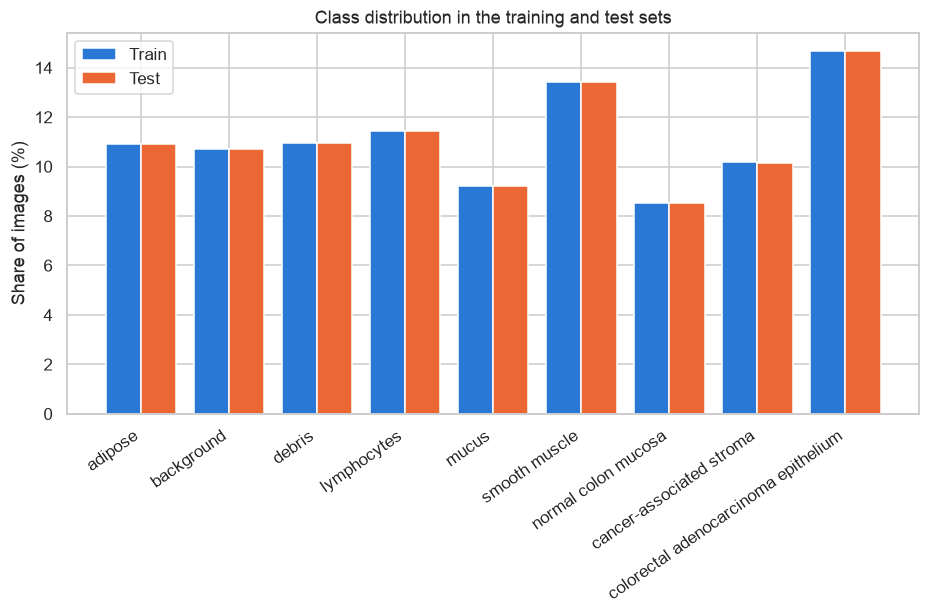

In [6]:
def class_counts(labels):
    """Number of examples per class, in label order."""
    return np.bincount(labels, minlength=N_CLASSES)


train_counts, test_counts = class_counts(y_train), class_counts(y_test)
class_dist = pd.DataFrame(
    {
        "class": CLASS_NAMES,
        "train count": train_counts,
        "train %": 100 * train_counts / train_counts.sum(),
        "test count": test_counts,
        "test %": 100 * test_counts / test_counts.sum(),
    }
).round(2)
display(class_dist)
print(f"Imbalance ratio (largest / smallest training class): {train_counts.max() / train_counts.min():.2f}")

fig, ax = plt.subplots(figsize=(10, 4.5))
positions = np.arange(N_CLASSES)
bar_width = 0.4
ax.bar(positions - bar_width / 2, class_dist["train %"], bar_width, label="Train", color=SERIES_BLUE)
ax.bar(positions + bar_width / 2, class_dist["test %"], bar_width, label="Test", color=SERIES_ORANGE)
ax.set_xticks(positions, CLASS_NAMES, rotation=35, ha="right")
ax.set_ylabel("Share of images (%)")
ax.set_title("Class distribution in the training and test sets")
ax.legend()
save_fig(fig, "class_distribution")
plt.show()

### 1.3 Sample images from each class
Eight random images per class, to see what distinguishes the tissue types and which classes look alike.

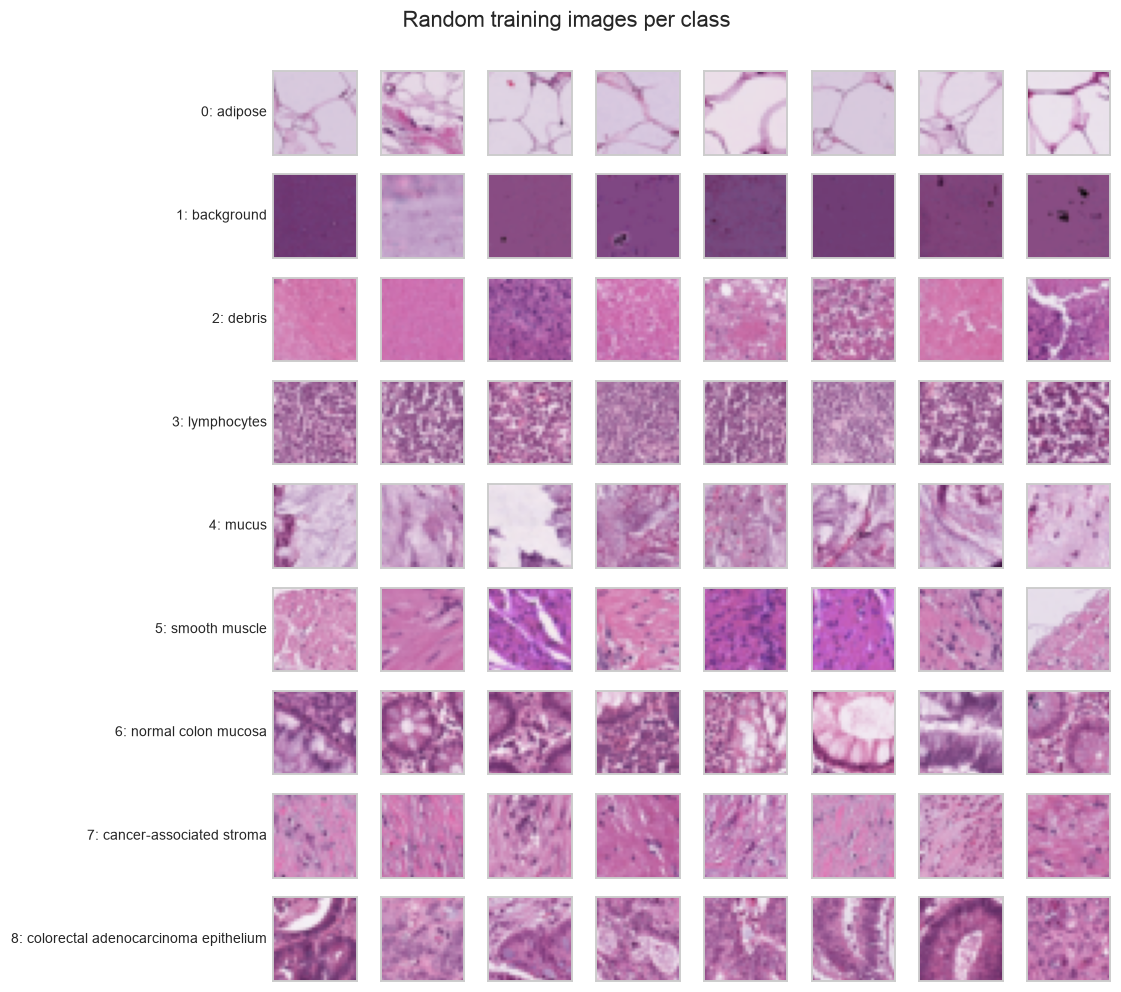

In [7]:
def plot_samples_per_class(images, labels, n_per_class=8, seed=RANDOM_STATE):
    """Grid with one row per class and n_per_class random examples."""
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(N_CLASSES, n_per_class, figsize=(n_per_class * 1.0 + 2.5, N_CLASSES * 1.0))
    for class_idx, class_name in enumerate(CLASS_NAMES):
        chosen = rng.choice(np.flatnonzero(labels == class_idx), n_per_class, replace=False)
        for col, img_idx in enumerate(chosen):
            ax = axes[class_idx, col]
            ax.imshow(images[img_idx])
            ax.set_xticks([])
            ax.set_yticks([])
        axes[class_idx, 0].set_ylabel(f"{class_idx}: {class_name}", rotation=0, ha="right", va="center", fontsize=9)
    fig.suptitle("Random training images per class", y=1.0)
    fig.tight_layout()
    return fig


fig = plot_samples_per_class(X_train, y_train)
save_fig(fig, "samples_per_class")
plt.show()

### 1.4 Spatial structure: are the images centred?
If images contained a centred object, the per-class mean image would show a clear shape. A nearly uniform mean image means the classes are defined by texture spread across the whole patch, so position carries little information.

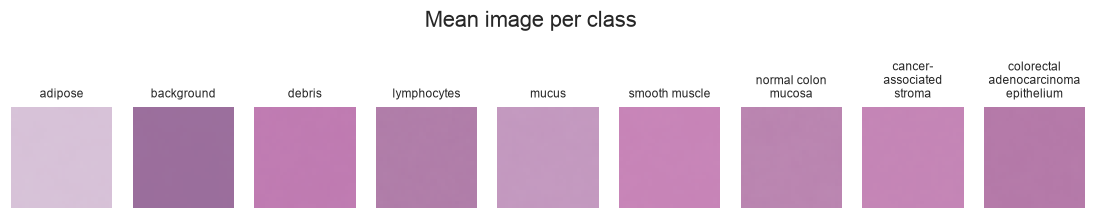

,class,spatial std of class-mean image,mean within-image std
0,adipose,0.37,20.44
1,background,0.26,6.99
2,debris,0.37,18.88
3,lymphocytes,0.45,25.20
4,mucus,0.44,23.56
5,smooth muscle,0.36,20.54
6,normal colon mucosa,0.62,30.18
7,cancer-associated stroma,0.30,17.49
8,colorectal adenocarcinoma epithelium,0.42,27.59


In [8]:
class_mean_images = np.stack([X_train[y_train == c].mean(axis=0) for c in range(N_CLASSES)])

fig, axes = plt.subplots(1, N_CLASSES, figsize=(N_CLASSES * 1.4, 2.4))
for class_idx, ax in enumerate(axes):
    ax.imshow(class_mean_images[class_idx].astype(np.uint8))
    ax.set_title(textwrap.fill(CLASS_NAMES[class_idx], 14), fontsize=8)
    ax.axis("off")
fig.suptitle("Mean image per class", y=1.05)
save_fig(fig, "mean_image_per_class")
plt.show()

# How much does the mean image vary across pixel positions, compared with within individual images?
spatial_std_of_mean = class_mean_images.std(axis=(1, 2)).mean(axis=1)
within_image_std = np.array([X_train[y_train == c].std(axis=(1, 2)).mean() for c in range(N_CLASSES)])
display(
    pd.DataFrame(
        {
            "class": CLASS_NAMES,
            "spatial std of class-mean image": spatial_std_of_mean,
            "mean within-image std": within_image_std,
        }
    ).round(2)
)

### 1.5 Colour and pixel intensity
Haematoxylin and eosin (H&E) staining colours nuclei purple and cytoplasm/stroma pink, so colour may separate some classes. Compare the per-image mean intensity of each channel across classes.

Red        Green         Blue      
                                       mean   std   mean   std   mean   std
class                                                                      
adipose                               215.4   8.0  194.3  12.1  216.3   7.9
background                            155.2  46.0  110.9  59.2  156.8  44.5
debris                                191.9  15.7  123.8  22.1  178.1  17.4
lymphocytes                           176.7  10.4  126.0  13.9  169.4   9.9
mucus                                 195.7  10.5  153.4  18.4  191.8  12.0
smooth muscle                         199.7  11.4  133.0  23.1  184.0  13.3
normal colon mucosa                   186.6  13.0  133.7  19.8  176.7  14.4
cancer-associated stroma              196.9  10.1  133.8  15.7  182.5  10.7
colorectal adenocarcinoma epithelium  181.0  13.1  122.2  17.7  169.1  13.3

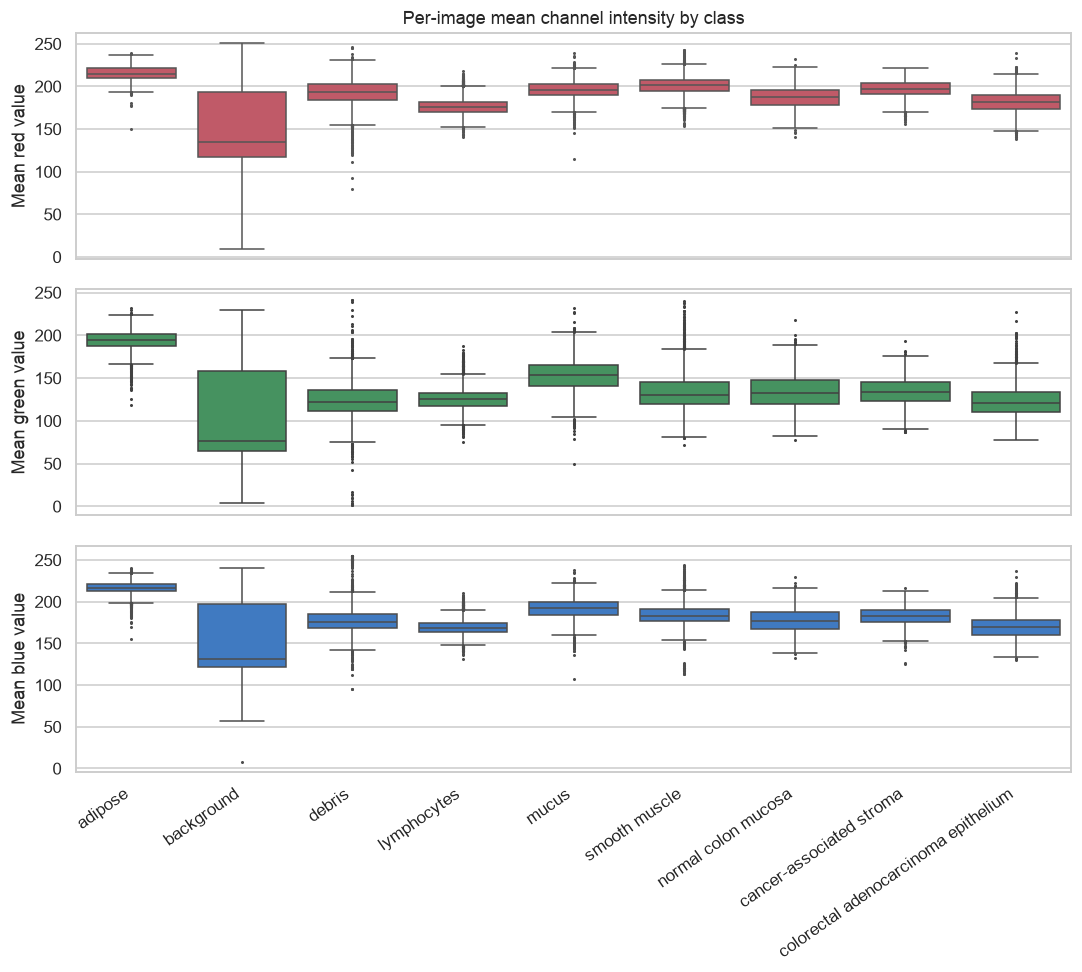

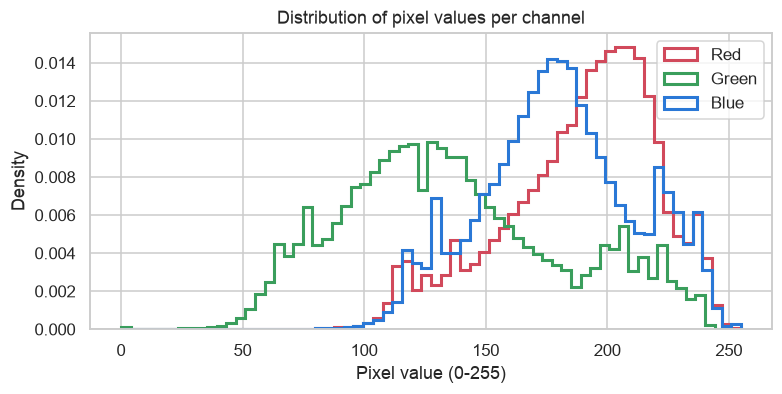

In [8]:
channel_names = list(CHANNEL_COLOURS)
image_channel_means = X_train.mean(axis=(1, 2))  # (n_images, 3)
channel_df = pd.DataFrame(image_channel_means, columns=channel_names)
channel_df["class"] = pd.Categorical([CLASS_NAMES[c] for c in y_train], categories=CLASS_NAMES)

# Table: mean and std of each channel per class
channel_summary = channel_df.groupby("class", observed=True)[channel_names].agg(["mean", "std"]).round(1)
display(channel_summary)

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for ax, channel in zip(axes, channel_names):
    sns.boxplot(data=channel_df, x="class", y=channel, ax=ax, color=CHANNEL_COLOURS[channel], fliersize=1, linewidth=1)
    ax.set_ylabel(f"Mean {channel.lower()} value")
    ax.set_xlabel("")
axes[-1].set_xticks(range(N_CLASSES), CLASS_NAMES, rotation=35, ha="right")
axes[0].set_title("Per-image mean channel intensity by class")
fig.tight_layout()
save_fig(fig, "channel_intensity_by_class")
plt.show()

# Overall pixel-value histograms per channel (train set)
fig, ax = plt.subplots(figsize=(8, 3.5))
for channel_idx, channel in enumerate(channel_names):
    ax.hist(X_train[..., channel_idx].ravel(), bins=64, histtype="step", linewidth=2,
            color=CHANNEL_COLOURS[channel], label=channel, density=True)
ax.set_xlabel("Pixel value (0-255)")
ax.set_ylabel("Density")
ax.set_title("Distribution of pixel values per channel")
ax.legend()
save_fig(fig, "pixel_histogram")
plt.show()

### 1.6 Class overlap in a low-dimensional projection
Project a random subsample of 4,500 flattened images onto the first two principal components. Each panel highlights one class over the rest, to show which classes occupy distinct regions and which overlap.

Variance explained by PC1 + PC2: 55.6%


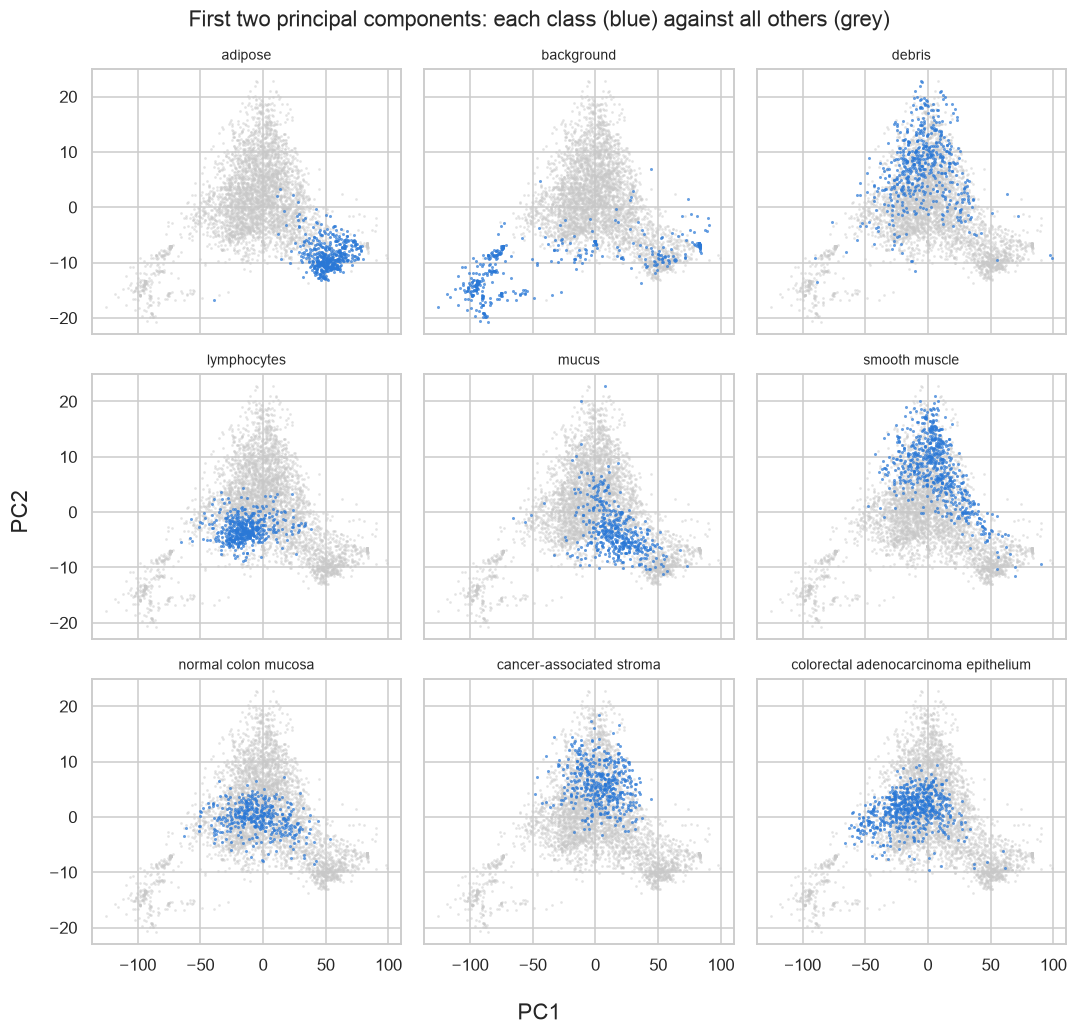

In [9]:
rng = np.random.default_rng(RANDOM_STATE)
subsample_idx = rng.choice(len(X_train), 4500, replace=False)
subsample_flat = X_train[subsample_idx].reshape(len(subsample_idx), -1).astype(np.float32) / 255.0
subsample_labels = y_train[subsample_idx]

pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
projected = pca_2d.fit_transform(StandardScaler().fit_transform(subsample_flat))
print(f"Variance explained by PC1 + PC2: {pca_2d.explained_variance_ratio_.sum():.1%}")

fig, axes = plt.subplots(3, 3, figsize=(10, 9.5), sharex=True, sharey=True)
for class_idx, ax in enumerate(axes.ravel()):
    in_class = subsample_labels == class_idx
    ax.scatter(projected[~in_class, 0], projected[~in_class, 1], s=3, color="#c8c8c8", alpha=0.5, linewidths=0)
    ax.scatter(projected[in_class, 0], projected[in_class, 1], s=4, color=SERIES_BLUE, alpha=0.7, linewidths=0)
    ax.set_title(CLASS_NAMES[class_idx], fontsize=9)
fig.supxlabel("PC1")
fig.supylabel("PC2")
fig.suptitle("First two principal components: each class (blue) against all others (grey)")
fig.tight_layout()
save_fig(fig, "pca_2d_by_class")
plt.show()

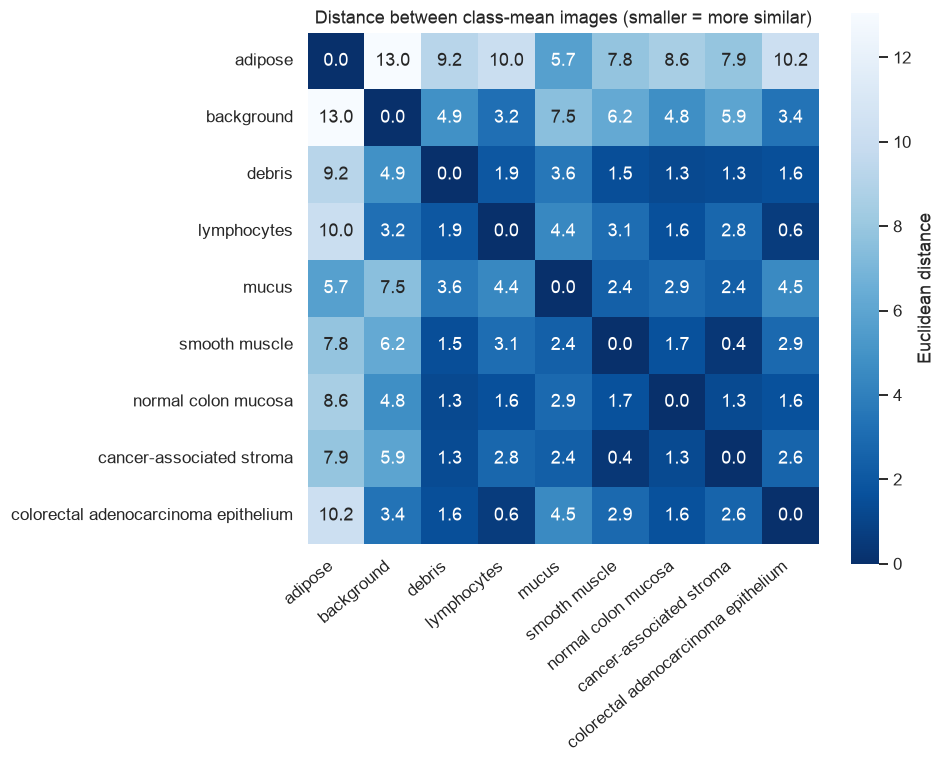

Five most similar class pairs (by mean image):
  smooth muscle - cancer-associated stroma: 0.38
  lymphocytes - colorectal adenocarcinoma epithelium: 0.65
  debris - normal colon mucosa: 1.25
  normal colon mucosa - cancer-associated stroma: 1.31
  debris - cancer-associated stroma: 1.33


In [10]:
# Which classes are closest on average? Euclidean distance between class-mean images (scaled to [0, 1]).
mean_flat = class_mean_images.reshape(N_CLASSES, -1) / 255.0
centroid_dist = np.linalg.norm(mean_flat[:, None, :] - mean_flat[None, :, :], axis=-1)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
sns.heatmap(centroid_dist, annot=True, fmt=".1f", cmap="Blues_r", square=True, cbar_kws={"label": "Euclidean distance"},
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_title("Distance between class-mean images (smaller = more similar)")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
save_fig(fig, "class_centroid_distance")
plt.show()

closest_pairs = sorted(
    ((centroid_dist[i, j], CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(N_CLASSES) for j in range(i + 1, N_CLASSES))
)[:5]
print("Five most similar class pairs (by mean image):")
for dist, class_a, class_b in closest_pairs:
    print(f"  {class_a} - {class_b}: {dist:.2f}")

**Key findings from the exploration**

- **Size and format.** 32,000 training and 8,000 test images, each 28 x 28 x 3 (RGB, `uint8` in [0, 255]), with no missing values. Flattened, each image has 2,352 features.
- **Mild class imbalance.** Class shares range from 8.5% (normal colon mucosa) to 14.7% (colorectal adenocarcinoma epithelium), an imbalance ratio of 1.72. The test set has the same proportions, so accuracy is meaningful, but macro-averaged metrics are also reported so smaller classes count equally.
- **Images are not centred; classes are defined by texture.** The class-mean images are almost uniform colour patches: their spatial standard deviation is below 0.7 intensity levels, against 7-30 within a single image. Position in the patch therefore carries little information. What matters is local texture (cell density, nuclei, fibres, fat cell walls) wherever it appears. This favours models with translation invariance, such as a CNN with weight sharing and pooling. Flattening an image for the SVM or MLP discards which pixels are neighbours.
- **Colour separates only some classes.** H&E staining colours every class pink-purple. Adipose is the brightest and most uniform class (mean R about 215, G about 194). Background is the darkest and by far the most variable (channel std 45-59), and includes a few pale patches. The remaining seven tissue classes have heavily overlapping mean colours (R 177-200, G 122-153), so colour alone cannot separate them and texture is needed.
- **Visually similar classes.** By distance between class-mean images, the closest pairs are smooth muscle vs cancer-associated stroma (0.38), both pink and fibrous, and lymphocytes vs colorectal adenocarcinoma epithelium (0.65), both dominated by dense purple nuclei. Debris, normal colon mucosa and stroma are also close. In the 2-D PCA projection only adipose and background form separate clusters; the other seven classes overlap in the centre.
- **Other difficulties.** At 28 x 28 pixels much of the cell-level detail is lost. Staining intensity varies between slides: debris ranges from pale pink to dense purple, and smooth muscle from light pink to saturated magenta. This within-class variation further blurs class boundaries.

### 1.7 Preprocessing

The same split is used by all three models so their validation and test results are directly comparable.

1. **Scaling to [0, 1]** (divide by 255): puts every pixel on the same small range, which keeps gradient-based training of the MLP and CNN stable and gives the SVM's distance-based kernel well-behaved inputs.
2. **Stratified train/validation split (80/20)** of the provided training set, `random_state=42`. The validation set is used for all hyperparameter tuning and early stopping. The test set is used only once, for the final models in Section 4. Stratification keeps the class proportions identical in both parts.
3. **Model-specific input shapes**:
    - SVM and MLP: images flattened to 2,352-dimensional vectors.
    - CNN: images kept as 28 x 28 x 3 tensors so convolutions can use the spatial layout.
4. **SVM only: standardisation and PCA** inside a scikit-learn `Pipeline`, so both are fitted on the training portion only (no leakage). An RBF-kernel SVM scales poorly with the number of features and samples, and many of the 2,352 pixel features are highly correlated; PCA keeps most of the variance in far fewer dimensions. The number of components is tuned in Section 3.

**Considered but not applied**
- *Resampling or class weights*: the imbalance ratio is only about 1.7, and the test set has the same class proportions, so we keep the data as is and report macro-averaged metrics alongside accuracy.
- *Greyscale conversion*: rejected, because mean colour differs clearly between classes (Section 1.5).
- *Resizing*: images are already small (28 x 28), so lowering the resolution would discard texture detail.
- *Data augmentation* (flips/rotations): possible for the CNN because tissue patches have no canonical orientation; this is left to the CNN section as a tunable option rather than a shared preprocessing step.

In [11]:
def scale_images(images):
    """Convert uint8 images in [0, 255] to float32 in [0, 1]. Returns a new array."""
    return images.astype(np.float32) / 255.0


def flatten_images(images):
    """Reshape (n, 28, 28, 3) images to (n, 2352) feature vectors. Returns a new array."""
    return images.reshape(len(images), -1)


def load_and_split(X_train_raw, y_train_raw, X_test_raw, y_test_raw,
                   val_fraction=VAL_FRACTION, random_state=RANDOM_STATE):
    """Shared preprocessing used by all three models.

    Scales images to [0, 1] and makes a stratified train/validation split of the
    provided training set. The raw arrays are left unchanged.
    """
    X_tr, X_va, y_tr, y_va = train_test_split(
        scale_images(X_train_raw), y_train_raw,
        test_size=val_fraction, stratify=y_train_raw, random_state=random_state,
    )
    return {
        "X_train": X_tr, "y_train": y_tr,
        "X_val": X_va, "y_val": y_va,
        "X_test": scale_images(X_test_raw), "y_test": y_test_raw.copy(),
    }


data = load_and_split(X_train, y_train, X_test, y_test)

# Image tensors (CNN) and flattened vectors (SVM, MLP)
X_tr_img, X_val_img, X_test_img = data["X_train"], data["X_val"], data["X_test"]
y_tr, y_val, y_te = data["y_train"], data["y_val"], data["y_test"]
X_tr_flat, X_val_flat, X_test_flat = (flatten_images(x) for x in (X_tr_img, X_val_img, X_test_img))

split_check = pd.DataFrame(
    {
        "train %": 100 * class_counts(y_tr) / len(y_tr),
        "validation %": 100 * class_counts(y_val) / len(y_val),
        "test %": 100 * class_counts(y_te) / len(y_te),
    },
    index=CLASS_NAMES,
).round(2)
print(f"Train: {len(y_tr)} | Validation: {len(y_val)} | Test: {len(y_te)}")
display(split_check)

Train: 25600 | Validation: 6400 | Test: 8000


,train %,validation %,test %
adipose,10.91,10.91,10.91
background,10.72,10.72,10.72
debris,10.95,10.95,10.96
lymphocytes,11.43,11.42,11.42
mucus,9.22,9.22,9.21
smooth muscle,13.41,13.41,13.40
normal colon mucosa,8.52,8.53,8.52
cancer-associated stroma,10.16,10.17,10.16
colorectal adenocarcinoma epithelium,14.68,14.67,14.68


**Choosing the PCA search range.** The cumulative explained variance of PCA (fitted on the training portion) shows how many components are needed to keep most of the information, and guides the values of `n_components` searched in Section 3.

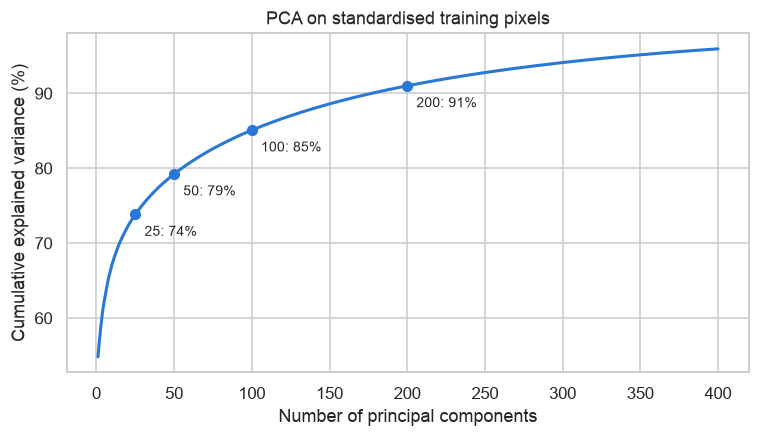

Components for 80% variance: 55
Components for 90% variance: 177
Components for 95% variance: 343


In [12]:
pca_full = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=400, random_state=RANDOM_STATE))])
pca_full.fit(X_tr_flat)
cumulative_variance = np.cumsum(pca_full.named_steps["pca"].explained_variance_ratio_)

PCA_CANDIDATES = [25, 50, 100, 200]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance * 100, color=SERIES_BLUE, linewidth=2)
for n_comp in PCA_CANDIDATES:
    ax.scatter(n_comp, cumulative_variance[n_comp - 1] * 100, color=SERIES_BLUE, s=40, zorder=3)
    ax.annotate(f"{n_comp}: {cumulative_variance[n_comp - 1]:.0%}", (n_comp, cumulative_variance[n_comp - 1] * 100),
                textcoords="offset points", xytext=(6, -14), fontsize=9)
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance (%)")
ax.set_title("PCA on standardised training pixels")
save_fig(fig, "pca_cumulative_variance")
plt.show()

for threshold in (0.8, 0.9, 0.95):
    print(f"Components for {threshold:.0%} variance: {np.searchsorted(cumulative_variance, threshold) + 1}")

Variance is spread over many components: 55 components keep 80% of the variance, 177 keep 90% and 343 keep 95%. The search therefore covers 25-200 components, from a very compact representation to one that keeps nearly 90% of the variance. The reconstructions below show the trade-off: 25-50 components keep colour and coarse structure but blur away fine texture (for example the lymphocyte nuclei), which is likely to limit the SVM on texture-defined classes.

### Examples of preprocessed data
Please print/display some examples of your preprocessed data here.

In [13]:
print("Preprocessed arrays:")
for name, array in [("X_tr_img (CNN)", X_tr_img), ("X_tr_flat (SVM/MLP)", X_tr_flat), ("y_tr", y_tr)]:
    print(f"  {name:22s} shape={array.shape}, dtype={array.dtype}, min={array.min():.2f}, max={array.max():.2f}")
print("\nFirst five scaled values of the first flattened image:", np.round(X_tr_flat[0, :5], 3))

Preprocessed arrays:
  X_tr_img (CNN)         shape=(25600, 28, 28, 3), dtype=float32, min=0.00, max=1.00
  X_tr_flat (SVM/MLP)    shape=(25600, 2352), dtype=float32, min=0.00, max=1.00
  y_tr                   shape=(25600,), dtype=uint8, min=0.00, max=8.00

First five scaled values of the first flattened image: [0.698 0.349 0.576 0.722 0.365]


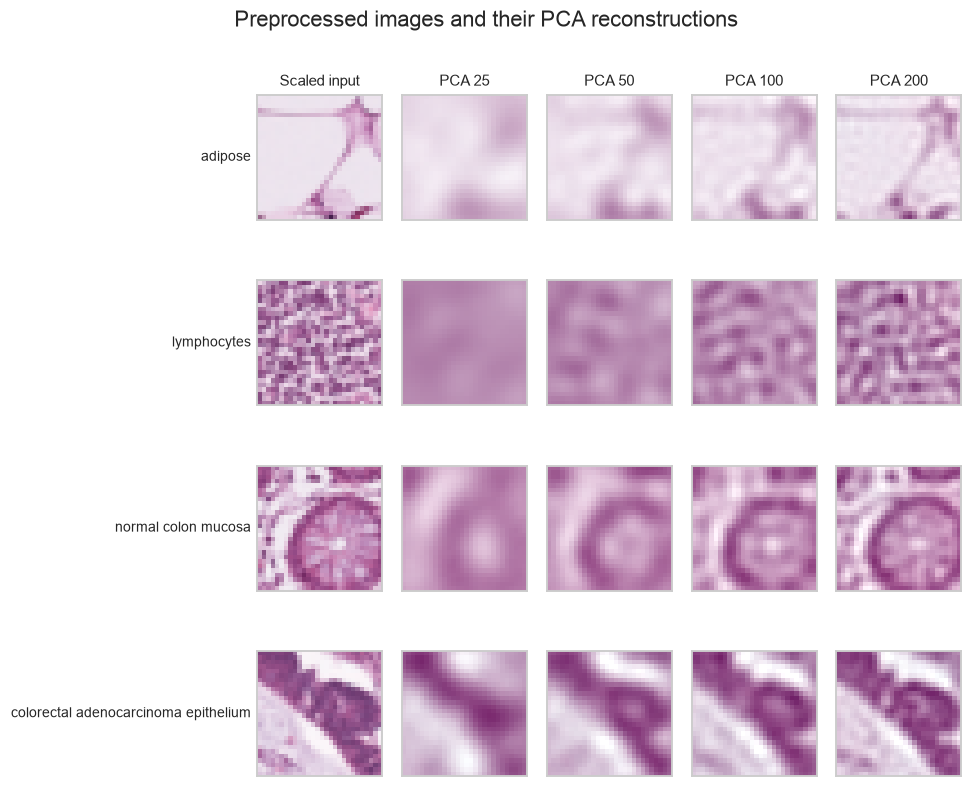

In [14]:
# Scaled images, and how they look after the SVM's standardise -> PCA -> reconstruct path.
# Keeping only the first k components of the fitted PCA is equivalent to PCA with k components.
scaler, pca_400 = pca_full.named_steps["scaler"], pca_full.named_steps["pca"]


def pca_reconstruct(flat_images, n_components):
    """Project standardised images onto the first n_components and map back to pixel space."""
    centred = scaler.transform(flat_images) - pca_400.mean_
    basis = pca_400.components_[:n_components]
    restored = (centred @ basis.T) @ basis + pca_400.mean_
    return np.clip(scaler.inverse_transform(restored), 0, 1)


example_idx = [np.flatnonzero(y_tr == c)[0] for c in (0, 3, 6, 8)]
fig, axes = plt.subplots(len(example_idx), 1 + len(PCA_CANDIDATES), figsize=(9, 7.5))
for row, img_idx in enumerate(example_idx):
    axes[row, 0].imshow(X_tr_img[img_idx])
    axes[row, 0].set_ylabel(CLASS_NAMES[y_tr[img_idx]], rotation=0, ha="right", va="center", fontsize=9)
    for col, n_comp in enumerate(PCA_CANDIDATES, start=1):
        axes[row, col].imshow(pca_reconstruct(X_tr_flat[img_idx:img_idx + 1], n_comp).reshape(28, 28, 3))
for col, title in enumerate(["Scaled input"] + [f"PCA {n}" for n in PCA_CANDIDATES]):
    axes[0, col].set_title(title, fontsize=10)
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Preprocessed images and their PCA reconstructions")
fig.tight_layout()
save_fig(fig, "pca_reconstructions")
plt.show()

## 2. Algorithm design and setup

### Algorithm of choice from first six weeks of course

We use a **support vector machine (SVM) with an RBF kernel**, preceded by standardisation and PCA (Week 6). The RBF kernel lets the SVM learn non-linear decision boundaries between tissue types, and maximising the margin gives it good generalisation on medium-sized datasets. PCA reduces the 2,352 correlated pixel features to a compact representation, which makes training on 25,600 images feasible. In rough trials on this split, the SVM was about as accurate as a random forest of 300 trees (both around 0.68 validation accuracy). We chose the SVM because its kernel and margin give a clearer theoretical contrast with the neural networks.

The helpers below are shared by all three models: timing a fit or a prediction, and computing the same metrics for every classifier.

In [15]:
def timed_fit(model, X, y, **fit_kwargs):
    """Fit a model and return (model, training time in seconds)."""
    start = time.perf_counter()
    model.fit(X, y, **fit_kwargs)
    return model, time.perf_counter() - start


def timed_predict(predict_fn, X):
    """Call a prediction function and return (predictions, prediction time in seconds)."""
    start = time.perf_counter()
    predictions = predict_fn(X)
    return predictions, time.perf_counter() - start


def evaluate_classifier(y_true, y_pred, model_name, train_time=None, predict_time=None):
    """Accuracy and macro-averaged precision/recall/F1, as one row for the results table."""
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro precision": precision,
        "macro recall": recall,
        "macro F1": f1,
        "train time (s)": train_time,
        "predict time (s)": predict_time,
    }


def plot_confusion(y_true, y_pred, title, filename=None):
    """Row-normalised confusion matrix (each row shows recall for that true class)."""
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, display_labels=CLASS_NAMES, normalize="true", values_format=".2f",
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(title)
    ax.grid(False)
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
    if filename:
        save_fig(fig, filename)
    plt.show()


def build_svm_pipeline(n_components=50, C=1.0, gamma="scale", memory=None):
    """Standardise -> PCA -> RBF-kernel SVM. PCA and scaling are fitted on training data only."""
    return Pipeline(
        [
            ("scaler", StandardScaler()),
            ("pca", PCA(n_components=n_components, random_state=RANDOM_STATE)),
            ("svm", SVC(kernel="rbf", C=C, gamma=gamma)),
        ],
        memory=memory,
    )

**Baseline SVM** with default-style settings (50 components, C = 1, gamma = 'scale'), trained on the training split and scored on the validation split. This is the reference point for tuning.

In [16]:
baseline_svm, baseline_train_time = timed_fit(build_svm_pipeline(), X_tr_flat, y_tr)
baseline_val_pred, baseline_pred_time = timed_predict(baseline_svm.predict, X_val_flat)

baseline_row = evaluate_classifier(y_val, baseline_val_pred, "SVM baseline (validation)",
                                   baseline_train_time, baseline_pred_time)
display(pd.DataFrame([baseline_row]).round(3))

,model,accuracy,macro precision,macro recall,macro F1,train time (s),predict time (s)
0,SVM baseline (validation),0.67,0.667,0.653,0.65,11.952,9.071


### Fully connected neural network

### Convolutional neural network

Two convolution blocks (16/32 filters), a 64-unit dense layer and dropout. Train on the shared split for up to 8 epochs; restore the weights with the lowest validation loss.


In [7]:
CNN_BASE_PARAMS = {
    "filters": 16,
    "kernel_size": 3,
    "dense_units": 64,
    "dropout": 0.2,
    "learning_rate": 1e-3,
}
CNN_BATCH_SIZE = 256
CNN_BASELINE_EPOCHS = 8


def build_cnn(params):
    model = keras.Sequential([
        keras.layers.Input(shape=X_tr_img.shape[1:]),
        keras.layers.Conv2D(params["filters"], params["kernel_size"], padding="same", activation="relu"),
        keras.layers.MaxPooling2D(),
        keras.layers.Conv2D(params["filters"] * 2, params["kernel_size"], padding="same", activation="relu"),
        keras.layers.MaxPooling2D(),
        keras.layers.Flatten(),
        keras.layers.Dense(params["dense_units"], activation="relu"),
        keras.layers.Dropout(params["dropout"]),
        keras.layers.Dense(N_CLASSES, activation="softmax"),
    ], name="cnn")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=params["learning_rate"]),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


class CNNEpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.started = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.perf_counter() - self.started)


Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       100,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │           585 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 106,089 (414.41 KB)

 Trainable params: 106,089 (414.41 KB)

 Non-trainable params: 0 (0.00 B)

...

100/100 - 2s - 21ms/step - accuracy: 0.6400 - loss: 0.9816 - val_accuracy: 0.6748 - val_loss: 0.9254


Epoch 8/8


100/100 - 2s - 21ms/step - accuracy: 0.6599 - loss: 0.9340 - val_accuracy: 0.6441 - val_loss: 0.9631


,model,accuracy,macro precision,macro recall,macro F1,train time (s),predict time (s),epochs run,best epoch (val loss),parameters,mean epoch time (s),batch size,filters,kernel_size,dense_units,dropout,learning_rate
0,CNN baseline (validation),0.6744,0.6736,0.6614,0.6581,17.8738,0.1907,8,6,106089,2.2277,256,16,3,64,0.2,0.001


,epoch,accuracy,loss,val_accuracy,val_loss,epoch_time_s
0,1,0.3512,1.7391,0.4580,1.4221,3.1711
1,2,0.4879,1.3672,0.5194,1.2443,2.1781
2,3,0.5432,1.2249,0.6036,1.0862,2.0770
3,4,0.5825,1.1248,0.6383,1.0183,2.1135
4,5,0.6052,1.0610,0.6570,0.9662,2.0154
5,6,0.6216,1.0268,0.6744,0.9189,2.0548
6,7,0.6400,0.9816,0.6748,0.9254,2.1059
7,8,0.6599,0.9340,0.6441,0.9631,2.1057


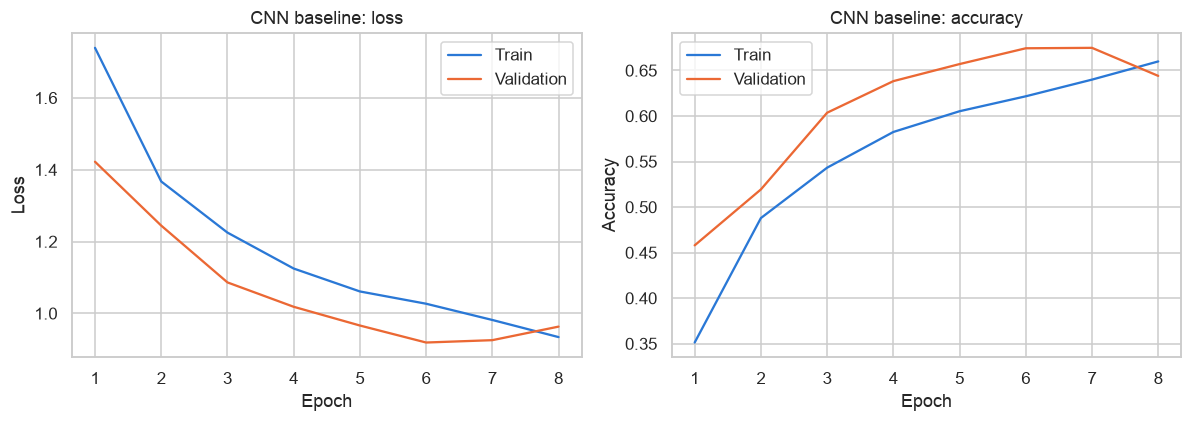

In [8]:
keras.backend.clear_session()
set_seeds()
cnn_baseline = build_cnn(CNN_BASE_PARAMS)
cnn_baseline.summary()
cnn_epoch_timer = CNNEpochTimer()
cnn_early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True,
)

cnn_fit_start = time.perf_counter()
cnn_history = cnn_baseline.fit(
    X_tr_img, y_tr,
    validation_data=(X_val_img, y_val),
    epochs=CNN_BASELINE_EPOCHS,
    batch_size=CNN_BATCH_SIZE,
    callbacks=[cnn_epoch_timer, cnn_early_stop],
    verbose=2,
)
cnn_train_time = time.perf_counter() - cnn_fit_start

cnn_val_prob, cnn_predict_time = timed_predict(
    lambda images: cnn_baseline.predict(images, batch_size=CNN_BATCH_SIZE, verbose=0),
    X_val_img,
)
cnn_val_pred = cnn_val_prob.argmax(axis=1)
cnn_baseline_results = evaluate_classifier(
    y_val, cnn_val_pred, "CNN baseline (validation)", cnn_train_time, cnn_predict_time,
)
cnn_baseline_results.update({
    "epochs run": len(cnn_history.history["loss"]),
    "best epoch (val loss)": int(np.argmin(cnn_history.history["val_loss"])) + 1,
    "parameters": cnn_baseline.count_params(),
    "mean epoch time (s)": float(np.mean(cnn_epoch_timer.times)),
    "batch size": CNN_BATCH_SIZE,
    **CNN_BASE_PARAMS,
})
pd.Series(cnn_baseline_results).to_json(RESULTS_DIR / "baseline_cnn.json")
display(pd.DataFrame([cnn_baseline_results]).round(4))

cnn_history_table = pd.DataFrame(cnn_history.history)
cnn_history_table.insert(0, "epoch", np.arange(1, len(cnn_history_table) + 1))
cnn_history_table["epoch_time_s"] = cnn_epoch_timer.times
cnn_history_table.to_csv(RESULTS_DIR / "cnn_baseline_history.csv", index=False)
display(cnn_history_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(axes, ["loss", "accuracy"], ["Loss", "Accuracy"]):
    ax.plot(cnn_history_table["epoch"], cnn_history_table[metric], label="Train", color=SERIES_BLUE)
    ax.plot(cnn_history_table["epoch"], cnn_history_table[f"val_{metric}"], label="Validation", color=SERIES_ORANGE)
    ax.set(xlabel="Epoch", ylabel=title, title=f"CNN baseline: {title.lower()}")
    ax.set_xticks(cnn_history_table["epoch"])
    ax.legend()
fig.tight_layout()
save_fig(fig, "cnn_baseline_learning_curves")
plt.show()


## 3. Hyperparameter tuning

### Algorithm of choice from first six weeks of course

**Search method.** An exhaustive grid search over three hyperparameters, each candidate trained on the training split and scored on the shared validation split (`PredefinedSplit`). We use one fixed validation set rather than k-fold cross-validation so the SVM is selected exactly as the MLP and CNN are, and because 64 candidates x 5 folds would take several times longer. Scaling and PCA are cached per `n_components`, so each is fitted once rather than once per candidate.

| Hyperparameter | Values | What it controls | Expected effect |
|---|---|---|---|
| `pca__n_components` | 25, 50, 100, 200 | dimensions kept (about 67%-88% of variance) | more components keep more detail but add noise and training time |
| `svm__C` | 0.1, 1, 10, 100 | penalty for margin violations | small C = wider margin, more regularised; large C fits the training data more closely and may overfit |
| `svm__gamma` | 1e-4, 3e-4, 1e-3, 3e-3 | RBF kernel width (1 / reach of each support vector) | small gamma = smoother boundaries; large gamma = very local, wiggly boundaries that may overfit |

The gamma range brackets scikit-learn's `'scale'` default (about 5e-4 for these inputs), found in rough trials. Training accuracy is recorded too, so overfitting can be seen.

> **Long-running cell (about 20-30 minutes on an 8-core laptop).** Its output is preserved; later sections do not depend on it.

In [17]:
SVM_PARAM_GRID = {
    "pca__n_components": PCA_CANDIDATES,
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [1e-4, 3e-4, 1e-3, 3e-3],
}
SVM_TUNING_CSV = RESULTS_DIR / "svm_tuning.csv"

# Train + validation stacked together; PredefinedSplit marks which rows are validation (fold 0)
X_search = np.concatenate([X_tr_flat, X_val_flat])
y_search = np.concatenate([y_tr, y_val])
validation_fold = np.concatenate([np.full(len(y_tr), -1), np.zeros(len(y_val), dtype=int)])

with tempfile.TemporaryDirectory() as cache_dir:
    svm_search = GridSearchCV(
        build_svm_pipeline(memory=cache_dir),
        SVM_PARAM_GRID,
        cv=PredefinedSplit(validation_fold),
        scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
        refit=False,
        return_train_score=True,
        n_jobs=4,
        verbose=1,
    )
    search_start = time.perf_counter()
    svm_search.fit(X_search, y_search)
    search_minutes = (time.perf_counter() - search_start) / 60

svm_tuning = pd.DataFrame(svm_search.cv_results_)[
    ["param_pca__n_components", "param_svm__C", "param_svm__gamma",
     "mean_test_accuracy", "mean_test_f1_macro", "mean_train_accuracy", "mean_fit_time", "mean_score_time"]
].rename(columns={
    "param_pca__n_components": "n_components", "param_svm__C": "C", "param_svm__gamma": "gamma",
    "mean_test_accuracy": "val_accuracy", "mean_test_f1_macro": "val_f1_macro",
    "mean_train_accuracy": "train_accuracy", "mean_fit_time": "fit_time_s", "mean_score_time": "score_time_s",
})
svm_tuning.to_csv(SVM_TUNING_CSV, index=False)

print(f"Grid search finished in {search_minutes:.1f} minutes ({len(svm_tuning)} candidates).")
display(svm_tuning.sort_values("val_accuracy", ascending=False).head(10).round(4))

Fitting 1 folds for each of 64 candidates, totalling 64 fits


Grid search finished in 29.1 minutes (64 candidates).


,n_components,C,gamma,val_accuracy,val_f1_macro,train_accuracy,fit_time_s,score_time_s
10,25,10.0,0.0010,0.6859,0.6782,0.8288,11.5303,5.7825
6,25,1.0,0.0010,0.6833,0.6705,0.7301,9.7515,6.3501
9,25,10.0,0.0003,0.6827,0.6689,0.7348,10.1077,5.7825
7,25,1.0,0.0030,0.6825,0.6741,0.8157,13.3693,6.3636
12,25,100.0,0.0001,0.6808,0.6663,0.7266,13.2151,5.6620
13,25,100.0,0.0003,0.6788,0.6702,0.8028,15.5943,5.5119
25,50,10.0,0.0003,0.6784,0.6657,0.7741,15.7129,9.0228
26,50,10.0,0.0010,0.6781,0.6721,0.8948,19.0130,9.4514
22,50,1.0,0.0010,0.6778,0.6631,0.7630,16.7641,9.7261
11,25,10.0,0.0030,0.6748,0.6706,0.9281,15.6850,6.3194


**Tuning results.** The plots below read the saved results file, so they can be redrawn without rerunning the search.

Best: n_components=25, C=10, gamma=0.001 -> validation accuracy 0.6859, macro F1 0.6782


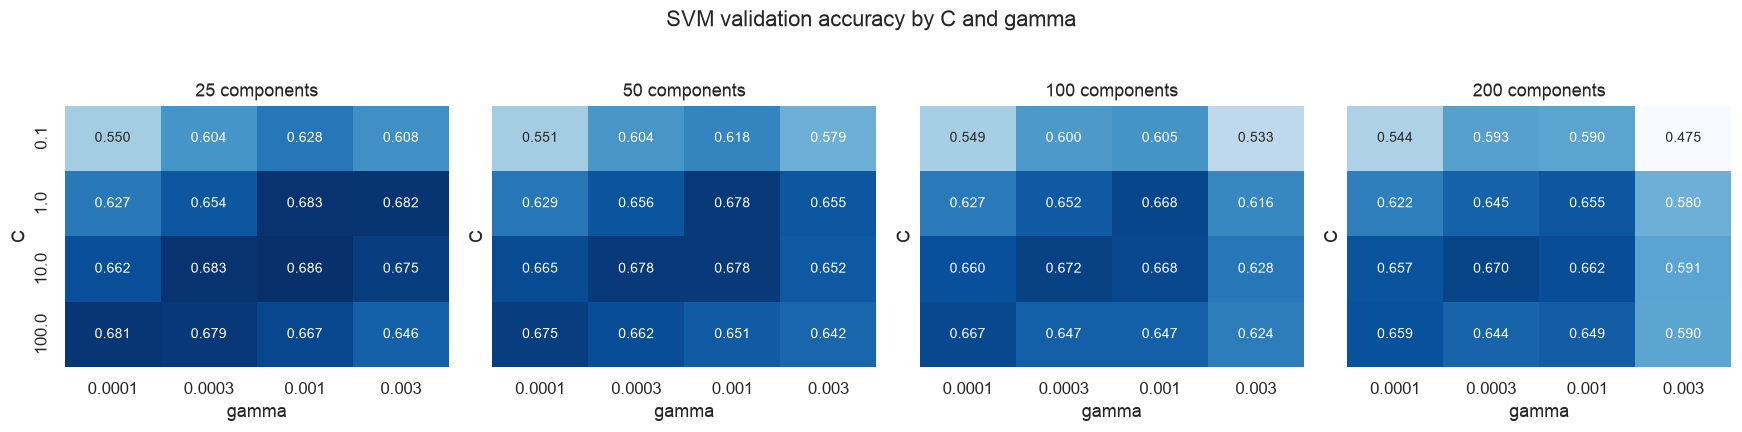

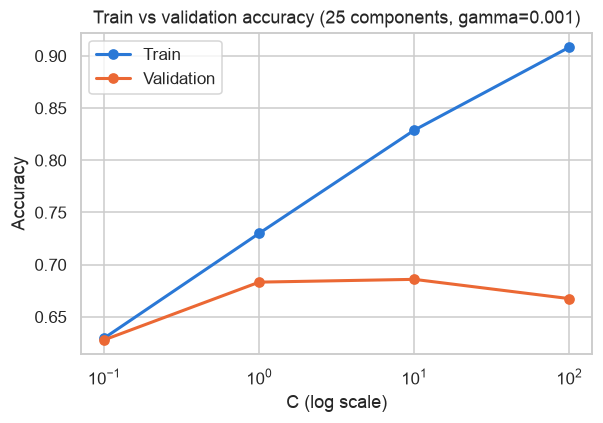

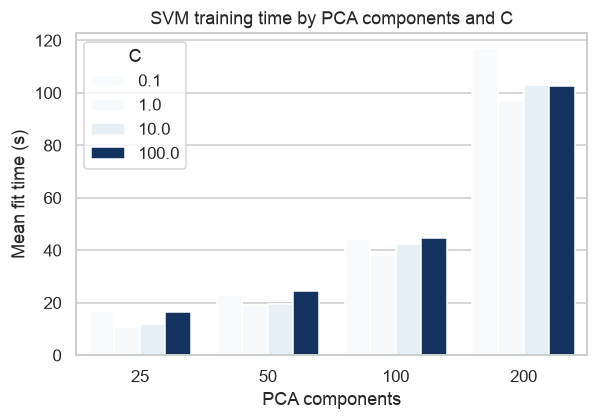

,best val accuracy,mean fit time (s),mean score time (s)
n_components,,,
25,0.686,14.022,6.388
50,0.678,21.328,9.927
100,0.672,42.319,13.122
200,0.670,104.733,16.084


In [18]:
SVM_TUNING_CSV = RESULTS_DIR / "svm_tuning.csv"
if not SVM_TUNING_CSV.exists():
    print("No saved SVM tuning results; run the grid search cell above first.")
else:
    tuning = pd.read_csv(SVM_TUNING_CSV)
    best = tuning.loc[tuning["val_accuracy"].idxmax()]
    print(f"Best: n_components={int(best.n_components)}, C={best.C:g}, gamma={best.gamma:g} "
          f"-> validation accuracy {best.val_accuracy:.4f}, macro F1 {best.val_f1_macro:.4f}")

    # Validation accuracy over C x gamma, one panel per number of PCA components
    components = sorted(tuning["n_components"].unique())
    fig, axes = plt.subplots(1, len(components), figsize=(4 * len(components), 3.8), sharey=True)
    vmin, vmax = tuning["val_accuracy"].min(), tuning["val_accuracy"].max()
    for ax, n_comp in zip(axes, components):
        grid = tuning[tuning["n_components"] == n_comp].pivot(index="C", columns="gamma", values="val_accuracy")
        sns.heatmap(grid, annot=True, fmt=".3f", cmap="Blues", vmin=vmin, vmax=vmax, cbar=False, ax=ax,
                    annot_kws={"fontsize": 9})
        ax.set_title(f"{n_comp} components")
        ax.set_xticklabels([f"{g:g}" for g in grid.columns])
    fig.suptitle("SVM validation accuracy by C and gamma", y=1.03)
    fig.tight_layout()
    save_fig(fig, "svm_tuning_heatmaps")
    plt.show()

    # Overfitting: train vs validation accuracy as C grows (best n_components and gamma)
    subset = tuning[(tuning["n_components"] == best.n_components) & (tuning["gamma"] == best.gamma)].sort_values("C")
    fig, ax = plt.subplots(figsize=(6, 3.8))
    ax.plot(subset["C"], subset["train_accuracy"], marker="o", color=SERIES_BLUE, linewidth=2, label="Train")
    ax.plot(subset["C"], subset["val_accuracy"], marker="o", color=SERIES_ORANGE, linewidth=2, label="Validation")
    ax.set_xscale("log")
    ax.set_xlabel("C (log scale)")
    ax.set_ylabel("Accuracy")
    ax.set_title(f"Train vs validation accuracy ({int(best.n_components)} components, gamma={best.gamma:g})")
    ax.legend()
    save_fig(fig, "svm_train_vs_val_C")
    plt.show()

    # Runtime: mean fit time per candidate, by number of components and C
    fig, ax = plt.subplots(figsize=(6, 3.8))
    sns.barplot(data=tuning, x="n_components", y="fit_time_s", hue="C", palette="Blues", ax=ax, errorbar=None)
    ax.set_xlabel("PCA components")
    ax.set_ylabel("Mean fit time (s)")
    ax.set_title("SVM training time by PCA components and C")
    ax.legend(title="C")
    save_fig(fig, "svm_fit_time")
    plt.show()

    summary = tuning.groupby("n_components")[["val_accuracy", "fit_time_s", "score_time_s"]].agg(
        {"val_accuracy": "max", "fit_time_s": "mean", "score_time_s": "mean"}).round(3)
    display(summary.rename(columns={"val_accuracy": "best val accuracy", "fit_time_s": "mean fit time (s)",
                                    "score_time_s": "mean score time (s)"}))

**Refinement search (coarse-to-fine).** The coarse grid's best result used 25 components, the smallest value searched, so the optimum may lie below the grid's edge. A second, finer grid around that point checks this: fewer and intermediate component counts, and C and gamma values between the coarse steps. These fits are cheap because the inputs are small.

| Hyperparameter | Values |
|---|---|
| `pca__n_components` | 10, 15, 25, 35 |
| `svm__C` | 3, 10, 30 |
| `svm__gamma` | 5e-4, 1e-3, 2e-3 |

In [17]:
SVM_FINE_GRID = {
    "pca__n_components": [10, 15, 25, 35],
    "svm__C": [3, 10, 30],
    "svm__gamma": [5e-4, 1e-3, 2e-3],
}
SVM_FINE_CSV = RESULTS_DIR / "svm_tuning_fine.csv"

# Same stacked train + validation arrays and PredefinedSplit as the coarse search
X_search = np.concatenate([X_tr_flat, X_val_flat])
y_search = np.concatenate([y_tr, y_val])
validation_fold = np.concatenate([np.full(len(y_tr), -1), np.zeros(len(y_val), dtype=int)])

with tempfile.TemporaryDirectory() as cache_dir:
    svm_fine_search = GridSearchCV(
        build_svm_pipeline(memory=cache_dir),
        SVM_FINE_GRID,
        cv=PredefinedSplit(validation_fold),
        scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
        refit=False,
        return_train_score=True,
        n_jobs=4,
        verbose=1,
    )
    search_start = time.perf_counter()
    svm_fine_search.fit(X_search, y_search)
    search_minutes = (time.perf_counter() - search_start) / 60

svm_fine = pd.DataFrame(svm_fine_search.cv_results_)[
    ["param_pca__n_components", "param_svm__C", "param_svm__gamma",
     "mean_test_accuracy", "mean_test_f1_macro", "mean_train_accuracy", "mean_fit_time", "mean_score_time"]
].rename(columns={
    "param_pca__n_components": "n_components", "param_svm__C": "C", "param_svm__gamma": "gamma",
    "mean_test_accuracy": "val_accuracy", "mean_test_f1_macro": "val_f1_macro",
    "mean_train_accuracy": "train_accuracy", "mean_fit_time": "fit_time_s", "mean_score_time": "score_time_s",
})
svm_fine.to_csv(SVM_FINE_CSV, index=False)

print(f"Refinement search finished in {search_minutes:.1f} minutes ({len(svm_fine)} candidates).")
display(svm_fine.sort_values("val_accuracy", ascending=False).head(10).round(4))

Fitting 1 folds for each of 36 candidates, totalling 36 fits


Refinement search finished in 6.6 minutes (36 candidates).


,n_components,C,gamma,val_accuracy,val_f1_macro,train_accuracy,fit_time_s,score_time_s
19,25,3,0.0010,0.6916,0.6834,0.7828,10.8107,6.0096
28,35,3,0.0010,0.6911,0.6813,0.8081,12.3342,7.5675
11,15,3,0.0020,0.6900,0.6813,0.7888,9.6944,5.5028
20,25,3,0.0020,0.6900,0.6830,0.8426,12.8194,6.1248
10,15,3,0.0010,0.6897,0.6793,0.7405,8.8764,5.5244
15,15,30,0.0005,0.6895,0.6802,0.7579,10.3524,5.1663
21,25,10,0.0005,0.6886,0.6790,0.7701,10.8889,5.7673
4,10,10,0.0010,0.6878,0.6764,0.7348,7.9284,4.9013
29,35,3,0.0020,0.6877,0.6802,0.8722,15.4802,8.2328
12,15,10,0.0005,0.6875,0.6756,0.7308,8.8647,5.3190


Best overall: n_components=25, C=3, gamma=0.001 -> validation accuracy 0.6916, macro F1 0.6834


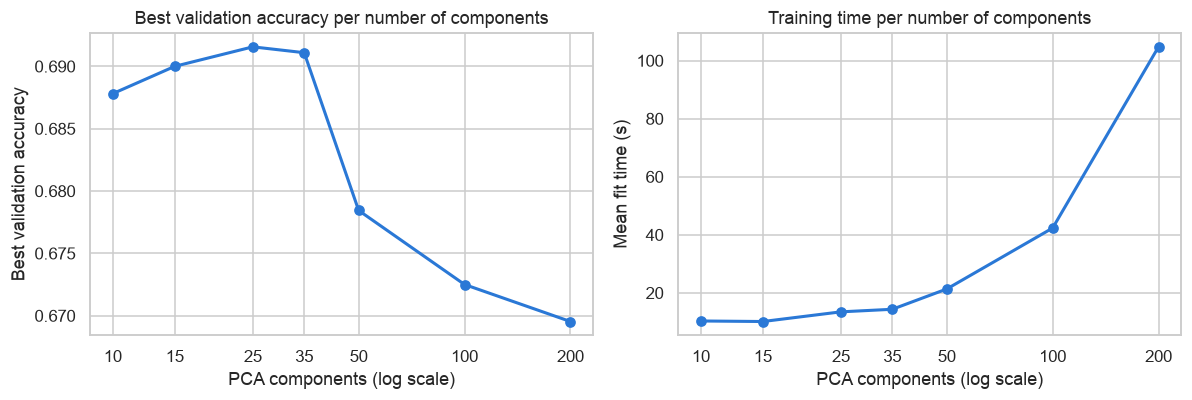

,n_components,best_val_accuracy,mean_fit_time_s
0,10,0.6878,10.3066
1,15,0.6900,10.1187
2,25,0.6916,13.4528
3,35,0.6911,14.3362
4,50,0.6784,21.3277
5,100,0.6725,42.3187
6,200,0.6695,104.7333


In [18]:
SVM_FINE_CSV = RESULTS_DIR / "svm_tuning_fine.csv"
if not SVM_FINE_CSV.exists():
    print("No saved refinement results; run the refinement search cell above first.")
else:
    fine = pd.read_csv(SVM_FINE_CSV)
    best_fine = fine.loc[fine["val_accuracy"].idxmax()]
    print(f"Best overall: n_components={int(best_fine.n_components)}, C={best_fine.C:g}, gamma={best_fine.gamma:g} "
          f"-> validation accuracy {best_fine.val_accuracy:.4f}, macro F1 {best_fine.val_f1_macro:.4f}")

    # Best validation accuracy for each number of components, across both searches
    coarse = pd.read_csv(RESULTS_DIR / "svm_tuning.csv") if (RESULTS_DIR / "svm_tuning.csv").exists() else fine.iloc[:0]
    combined = pd.concat([coarse, fine]).groupby("n_components").agg(
        best_val_accuracy=("val_accuracy", "max"), mean_fit_time_s=("fit_time_s", "mean")).reset_index()

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    axes[0].plot(combined["n_components"], combined["best_val_accuracy"], marker="o", color=SERIES_BLUE, linewidth=2)
    axes[0].set_xscale("log")
    axes[0].set_xticks(combined["n_components"], [str(n) for n in combined["n_components"]])
    axes[0].set_xlabel("PCA components (log scale)")
    axes[0].set_ylabel("Best validation accuracy")
    axes[0].set_title("Best validation accuracy per number of components")
    axes[1].plot(combined["n_components"], combined["mean_fit_time_s"], marker="o", color=SERIES_BLUE, linewidth=2)
    axes[1].set_xscale("log")
    axes[1].set_xticks(combined["n_components"], [str(n) for n in combined["n_components"]])
    axes[1].set_xlabel("PCA components (log scale)")
    axes[1].set_ylabel("Mean fit time (s)")
    axes[1].set_title("Training time per number of components")
    fig.tight_layout()
    save_fig(fig, "svm_components_accuracy_time")
    plt.show()

    display(combined.round(4))

### Fully connected neural network

### Convolutional neural network

Grid search over filters, learning rate and dropout (12 combinations), using the shared train/validation split. Each trial runs for up to 20 epochs with patience 4 and restores the lowest validation-loss weights; rank the restored models by validation accuracy, then macro F1. The plots read saved results.


In [8]:
import json
from sklearn.model_selection import ParameterGrid

CNN_PARAM_GRID = {
    "filters": [16, 32],
    "learning_rate": [3e-4, 1e-3, 3e-3],
    "dropout": [0.2, 0.4],
}
CNN_TUNING_EPOCHS = 20
CNN_TUNING_PATIENCE = 4
cnn_candidates = list(ParameterGrid(CNN_PARAM_GRID))
(RESULTS_DIR / "cnn_tuning_summary.json").unlink(missing_ok=True)
cnn_trial_rows, cnn_trial_histories = [], []
cnn_best_key, cnn_best_model = None, None
cnn_search_start = time.perf_counter()

for cnn_trial_id, cnn_candidate in enumerate(cnn_candidates, start=1):
    keras.backend.clear_session()
    set_seeds()
    cnn_params = {**CNN_BASE_PARAMS, **cnn_candidate}
    cnn_trial_model = build_cnn(cnn_params)
    cnn_trial_timer = CNNEpochTimer()
    cnn_trial_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=CNN_TUNING_PATIENCE, restore_best_weights=True,
    )
    print(f"Trial {cnn_trial_id}/{len(cnn_candidates)}: {cnn_candidate}", flush=True)
    cnn_trial_start = time.perf_counter()
    cnn_trial_history = cnn_trial_model.fit(
        X_tr_img, y_tr, validation_data=(X_val_img, y_val),
        epochs=CNN_TUNING_EPOCHS, batch_size=CNN_BATCH_SIZE,
        callbacks=[cnn_trial_timer, cnn_trial_stop], verbose=0,
    )
    cnn_trial_fit_time = time.perf_counter() - cnn_trial_start
    cnn_trial_prob, cnn_trial_predict_time = timed_predict(
        lambda images: cnn_trial_model.predict(images, batch_size=CNN_BATCH_SIZE, verbose=0),
        X_val_img,
    )
    cnn_trial_metrics = evaluate_classifier(
        y_val, cnn_trial_prob.argmax(axis=1), "CNN tuning (validation)",
        cnn_trial_fit_time, cnn_trial_predict_time,
    )
    cnn_trial_train_loss, cnn_trial_train_acc = cnn_trial_model.evaluate(
        X_tr_img, y_tr, batch_size=CNN_BATCH_SIZE, verbose=0,
    )
    cnn_trial_best_epoch = int(np.argmin(cnn_trial_history.history["val_loss"])) + 1
    cnn_trial_val_loss = float(cnn_trial_history.history["val_loss"][cnn_trial_best_epoch - 1])
    cnn_trial_rows.append({
        "trial": cnn_trial_id, **cnn_params, "batch_size": CNN_BATCH_SIZE,
        "epochs_run": len(cnn_trial_timer.times), "best_epoch": cnn_trial_best_epoch,
        "parameters": cnn_trial_model.count_params(),
        "train_accuracy": cnn_trial_train_acc, "train_loss": cnn_trial_train_loss,
        "val_accuracy": cnn_trial_metrics["accuracy"],
        "val_precision_macro": cnn_trial_metrics["macro precision"],
        "val_recall_macro": cnn_trial_metrics["macro recall"],
        "val_f1_macro": cnn_trial_metrics["macro F1"], "val_loss": cnn_trial_val_loss,
        "fit_time_s": cnn_trial_fit_time, "predict_time_s": cnn_trial_predict_time,
        "mean_epoch_time_s": float(np.mean(cnn_trial_timer.times)),
    })
    cnn_trial_frame = pd.DataFrame(cnn_trial_history.history)
    cnn_trial_frame.insert(0, "epoch", np.arange(1, len(cnn_trial_frame) + 1))
    cnn_trial_frame.insert(0, "trial", cnn_trial_id)
    cnn_trial_frame["epoch_time_s"] = cnn_trial_timer.times
    cnn_trial_histories.append(cnn_trial_frame)
    pd.DataFrame(cnn_trial_rows).to_csv(RESULTS_DIR / "cnn_tuning.csv", index=False)
    pd.concat(cnn_trial_histories, ignore_index=True).to_csv(RESULTS_DIR / "cnn_tuning_history.csv", index=False)
    cnn_trial_key = (cnn_trial_metrics["accuracy"], cnn_trial_metrics["macro F1"], -cnn_trial_val_loss, -cnn_trial_id)
    if cnn_best_key is None or cnn_trial_key > cnn_best_key:
        cnn_best_key, cnn_best_model = cnn_trial_key, cnn_trial_model
    print(f"  accuracy={cnn_trial_metrics['accuracy']:.4f}, macro F1={cnn_trial_metrics['macro F1']:.4f}, "
          f"epochs={len(cnn_trial_timer.times)}, best epoch={cnn_trial_best_epoch}, fit={cnn_trial_fit_time:.1f}s", flush=True)

cnn_search_seconds = time.perf_counter() - cnn_search_start
cnn_tuning = pd.DataFrame(cnn_trial_rows)
cnn_ranked = cnn_tuning.sort_values(
    ["val_accuracy", "val_f1_macro", "val_loss", "trial"], ascending=[False, False, True, True],
)
cnn_best = cnn_ranked.iloc[0]
cnn_best_params = {
    "filters": int(cnn_best["filters"]), "kernel_size": int(cnn_best["kernel_size"]),
    "dense_units": int(cnn_best["dense_units"]), "dropout": float(cnn_best["dropout"]),
    "learning_rate": float(cnn_best["learning_rate"]),
}
cnn_search_summary = {
    "search_grid": CNN_PARAM_GRID, "trials_completed": len(cnn_tuning),
    "max_epochs": CNN_TUNING_EPOCHS, "patience": CNN_TUNING_PATIENCE,
    "checkpoint_metric": "val_loss", "selection_metric": "validation accuracy; macro F1 breaks ties",
    "seed": RANDOM_STATE, "train_samples": len(y_tr), "validation_samples": len(y_val),
    "batch_size": CNN_BATCH_SIZE, "search_time_s": cnn_search_seconds,
    "total_fit_time_s": float(cnn_tuning["fit_time_s"].sum()),
    "best_trial": int(cnn_best["trial"]), "best_params": cnn_best_params,
    "best_epoch": int(cnn_best["best_epoch"]), "best_epochs_run": int(cnn_best["epochs_run"]),
    "best_val_accuracy": float(cnn_best["val_accuracy"]), "best_val_f1_macro": float(cnn_best["val_f1_macro"]),
    "best_fit_time_s": float(cnn_best["fit_time_s"]),
    "tensorflow": tf.__version__, "devices": [device.device_type for device in tf.config.list_physical_devices()],
}
(RESULTS_DIR / "cnn_tuning_summary.json").write_text(json.dumps(cnn_search_summary, indent=2))
print(f"Search completed: {len(cnn_tuning)} trials in {cnn_search_seconds / 60:.2f} minutes.")
print(f"Best parameters: {cnn_best_params}")
display(cnn_ranked[["trial", "filters", "learning_rate", "dropout", "val_accuracy", "val_f1_macro",
                    "epochs_run", "best_epoch", "fit_time_s"]].round(4))


Trial 1/12: {'dropout': 0.2, 'filters': 16, 'learning_rate': 0.0003}


  accuracy=0.6892, macro F1=0.6761, epochs=20, best epoch=20, fit=39.5s


Trial 2/12: {'dropout': 0.2, 'filters': 16, 'learning_rate': 0.001}


  accuracy=0.7633, macro F1=0.7518, epochs=20, best epoch=20, fit=40.3s


Trial 3/12: {'dropout': 0.2, 'filters': 16, 'learning_rate': 0.003}


...

  accuracy=0.7655, macro F1=0.7537, epochs=20, best epoch=19, fit=108.6s


Trial 12/12: {'dropout': 0.4, 'filters': 32, 'learning_rate': 0.003}


  accuracy=0.7480, macro F1=0.7423, epochs=20, best epoch=19, fit=104.9s


Search completed: 12 trials in 14.88 minutes.
Best parameters: {'filters': 16, 'kernel_size': 3, 'dense_units': 64, 'dropout': 0.2, 'learning_rate': 0.003}


,trial,filters,learning_rate,dropout,val_accuracy,val_f1_macro,epochs_run,best_epoch,fit_time_s
2,3,16,0.0030,0.2,0.7916,0.7834,20,18,40.6974
4,5,32,0.0010,0.2,0.7856,0.7797,20,20,93.5060
5,6,32,0.0030,0.2,0.7767,0.7668,20,20,90.9841
10,11,32,0.0010,0.4,0.7655,0.7537,20,19,108.6372
1,2,16,0.0010,0.2,0.7633,0.7518,20,20,40.3004
8,9,16,0.0030,0.4,0.7630,0.7482,16,12,40.8207
11,12,32,0.0030,0.4,0.7480,0.7423,20,19,104.8962
3,4,32,0.0003,0.2,0.7447,0.7385,20,20,94.1098
7,8,16,0.0010,0.4,0.7436,0.7313,20,19,53.5174
9,10,32,0.0003,0.4,0.7211,0.7103,20,18,113.0858


,val_accuracy,val_f1_macro,epochs_run,best_epoch,fit_time_s
baseline parameters (20-epoch cap),0.7633,0.7518,20.0,20.0,40.3004
best tuned parameters (20-epoch cap),0.7916,0.7834,20.0,18.0,40.6974


Full search: 892.5s; selected trial: 3


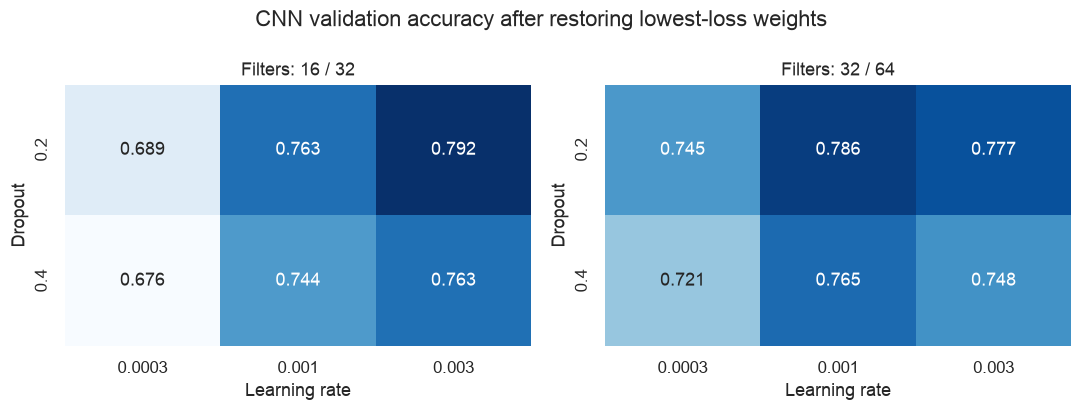

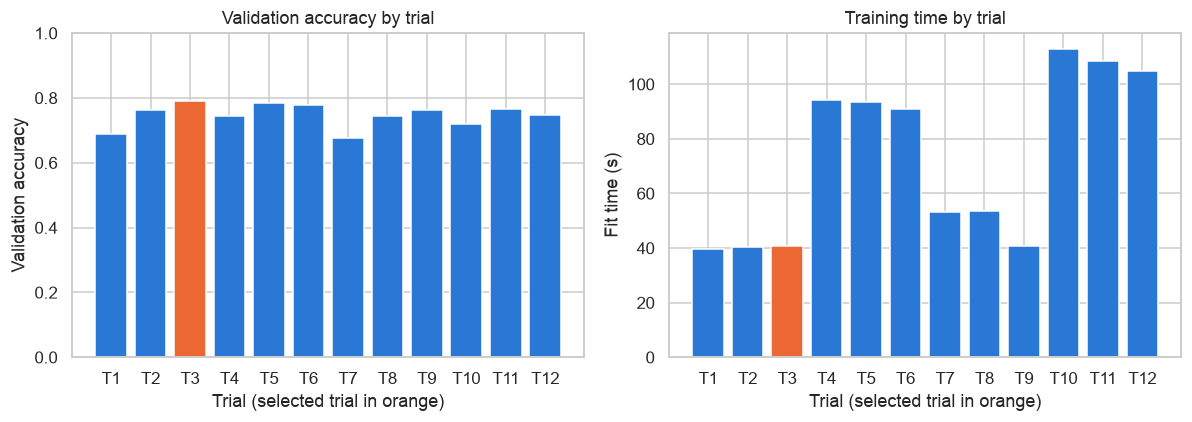

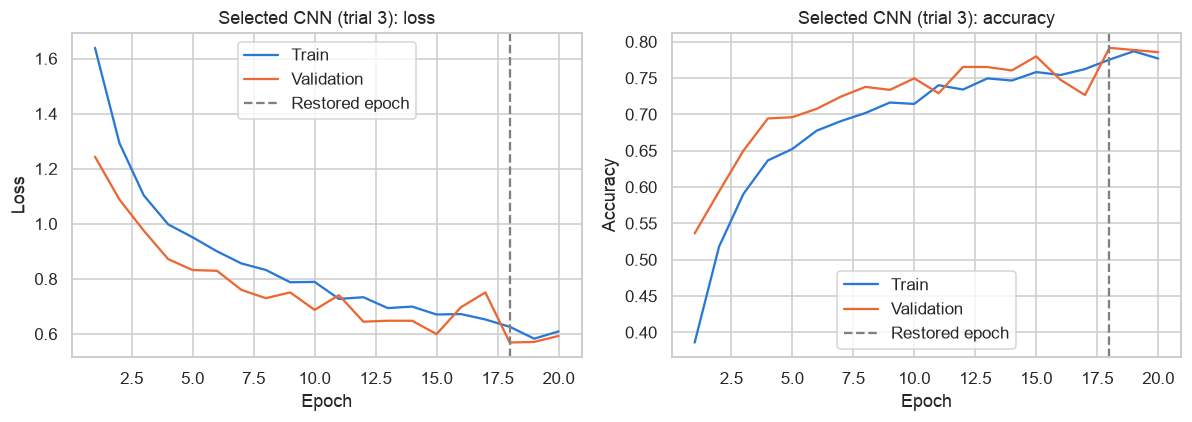

In [9]:
import json

cnn_result_files = [RESULTS_DIR / name for name in
                    ["cnn_tuning.csv", "cnn_tuning_history.csv", "cnn_tuning_summary.json"]]
if not all(path.exists() for path in cnn_result_files):
    print("No complete CNN tuning results; run the search cell above first.")
else:
    cnn_saved_tuning = pd.read_csv(cnn_result_files[0])
    cnn_saved_history = pd.read_csv(cnn_result_files[1])
    cnn_saved_summary = json.loads(cnn_result_files[2].read_text())
    cnn_best_trial = cnn_saved_summary["best_trial"]
    cnn_saved_best = cnn_saved_tuning.loc[cnn_saved_tuning["trial"] == cnn_best_trial].iloc[0]
    cnn_reference = cnn_saved_tuning.loc[
        (cnn_saved_tuning["filters"] == 16) & (cnn_saved_tuning["learning_rate"] == 1e-3)
        & (cnn_saved_tuning["dropout"] == 0.2)
    ].iloc[0]
    display(pd.DataFrame({
        "baseline parameters (20-epoch cap)": cnn_reference,
        "best tuned parameters (20-epoch cap)": cnn_saved_best,
    }).T[["val_accuracy", "val_f1_macro", "epochs_run", "best_epoch", "fit_time_s"]].round(4))
    print(f"Full search: {cnn_saved_summary['search_time_s']:.1f}s; selected trial: {cnn_best_trial}")

    cnn_filter_values = sorted(cnn_saved_tuning["filters"].unique())
    fig, axes = plt.subplots(1, len(cnn_filter_values), figsize=(10, 3.8), squeeze=False)
    for ax, filters in zip(axes.flat, cnn_filter_values):
        grid = cnn_saved_tuning.loc[cnn_saved_tuning["filters"] == filters].pivot(
            index="dropout", columns="learning_rate", values="val_accuracy",
        )
        sns.heatmap(grid, annot=True, fmt=".3f", cmap="Blues", cbar=False, ax=ax,
                    vmin=cnn_saved_tuning["val_accuracy"].min(), vmax=cnn_saved_tuning["val_accuracy"].max())
        ax.set(title=f"Filters: {filters} / {filters * 2}", xlabel="Learning rate", ylabel="Dropout")
        ax.set_xticklabels([f"{value:g}" for value in grid.columns])
    fig.suptitle("CNN validation accuracy after restoring lowest-loss weights")
    fig.tight_layout()
    save_fig(fig, "cnn_tuning_heatmaps")
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    cnn_trial_labels = [f"T{trial}" for trial in cnn_saved_tuning["trial"]]
    cnn_bar_colours = [SERIES_ORANGE if trial == cnn_best_trial else SERIES_BLUE
                       for trial in cnn_saved_tuning["trial"]]
    axes[0].bar(cnn_trial_labels, cnn_saved_tuning["val_accuracy"], color=cnn_bar_colours)
    axes[0].set(ylabel="Validation accuracy", ylim=(0, 1), title="Validation accuracy by trial")
    axes[1].bar(cnn_trial_labels, cnn_saved_tuning["fit_time_s"], color=cnn_bar_colours)
    axes[1].set(ylabel="Fit time (s)", title="Training time by trial")
    for ax in axes:
        ax.set_xlabel("Trial (selected trial in orange)")
    fig.tight_layout()
    save_fig(fig, "cnn_tuning_accuracy_time")
    plt.show()

    cnn_selected_history = cnn_saved_history.loc[cnn_saved_history["trial"] == cnn_best_trial]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, metric, title in zip(axes, ["loss", "accuracy"], ["Loss", "Accuracy"]):
        ax.plot(cnn_selected_history["epoch"], cnn_selected_history[metric], label="Train", color=SERIES_BLUE)
        ax.plot(cnn_selected_history["epoch"], cnn_selected_history[f"val_{metric}"], label="Validation", color=SERIES_ORANGE)
        ax.axvline(cnn_saved_summary["best_epoch"], color="grey", linestyle="--", label="Restored epoch")
        ax.set(xlabel="Epoch", ylabel=title, title=f"Selected CNN (trial {cnn_best_trial}): {title.lower()}")
        ax.legend()
    fig.tight_layout()
    save_fig(fig, "cnn_tuned_learning_curves")
    plt.show()


## 4. Final models
In this section, please ensure to include cells to train each model with its best hyperparmater combination independently of the hyperparameter tuning cells, i.e. don't rely on the hyperparameter tuning cells having been run.

### Algorithm of choice from first six weeks of course

The best combination from Section 3 (25 PCA components, C = 3, gamma = 1e-3; validation accuracy 0.692) is hard-coded here so this cell does not depend on the tuning cells. The model is trained on the same training split as the MLP and CNN (25,600 images) and evaluated once on the test set.

,model,accuracy,macro precision,macro recall,macro F1,train time (s),predict time (s),best n_components,best C,best gamma
0,SVM (PCA + RBF),0.6884,0.6846,0.6791,0.6792,9.3768,7.4442,25,3,0.001


                                      precision    recall  f1-score   support

                             adipose      0.860     0.961     0.908       873
                          background      0.936     0.890     0.913       858
                              debris      0.487     0.387     0.431       877
                         lymphocytes      0.930     0.904     0.917       914
                               mucus      0.652     0.617     0.634       737
                       smooth muscle      0.668     0.663     0.666      1072
                 normal colon mucosa      0.544     0.433     0.482       682
            cancer-associated stroma      0.503     0.549     0.525       813
colorectal adenocarcinoma epithelium      0.580     0.709     0.638      1174

                            accuracy                          0.688      8000
                           macro avg      0.685     0.679     0.679      8000
                        weighted avg      0.686     0.688     

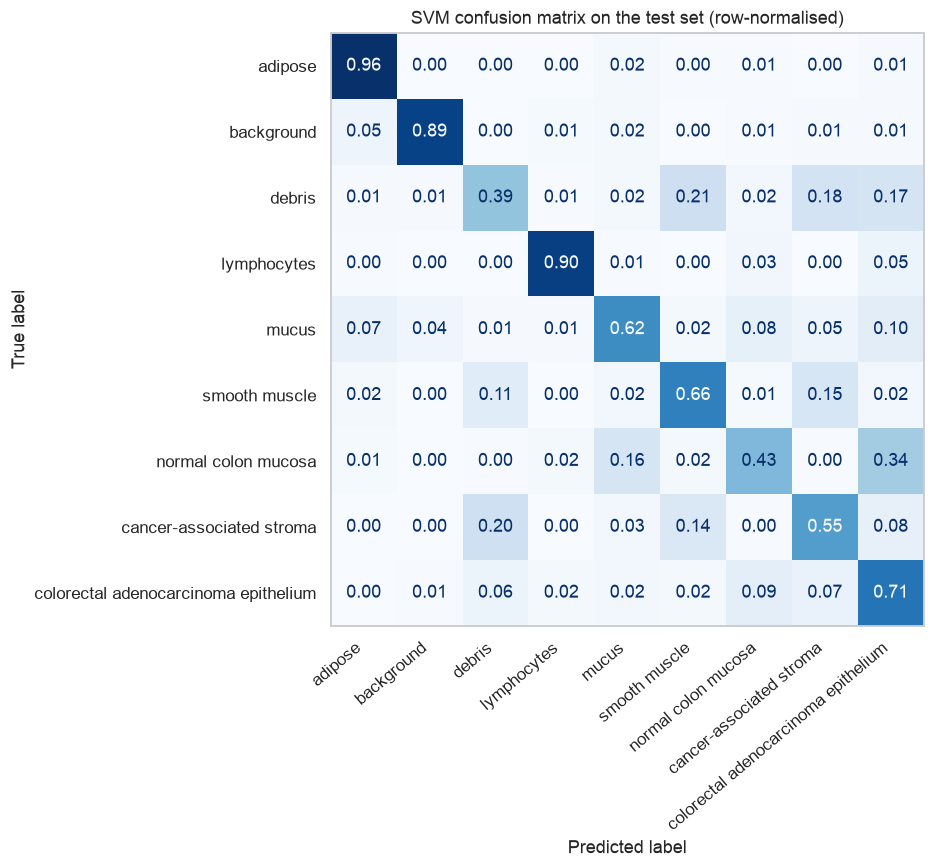

In [17]:
SVM_BEST_PARAMS = {"n_components": 25, "C": 3, "gamma": 1e-3}  # best validation accuracy (0.6916) in the Section 3 refinement search

set_seeds()
final_svm, svm_train_time = timed_fit(build_svm_pipeline(**SVM_BEST_PARAMS), X_tr_flat, y_tr)
svm_test_pred, svm_predict_time = timed_predict(final_svm.predict, X_test_flat)

svm_results = evaluate_classifier(y_te, svm_test_pred, "SVM (PCA + RBF)", svm_train_time, svm_predict_time)
svm_results.update({f"best {k}": v for k, v in SVM_BEST_PARAMS.items()})
pd.Series(svm_results).to_json(RESULTS_DIR / "final_svm.json")
display(pd.DataFrame([svm_results]).round(4))

print(classification_report(y_te, svm_test_pred, target_names=CLASS_NAMES, digits=3))
plot_confusion(y_te, svm_test_pred, "SVM confusion matrix on the test set (row-normalised)", "svm_confusion_matrix")

### Fully connected neural network

### Convolutional neural network

Rebuild the CNN with fixed best parameters, train on the shared training split, and restore the lowest validation-loss weights before evaluating the held-out test set. This section does not require running the hyperparameter search.


In [8]:
CNN_BEST_PARAMS = {
    "filters": 16,
    "kernel_size": 3,
    "dense_units": 64,
    "dropout": 0.2,
    "learning_rate": 0.003,
}
CNN_FINAL_BATCH_SIZE = 256
CNN_FINAL_EPOCHS = 20
CNN_FINAL_PATIENCE = 4

keras.backend.clear_session()
set_seeds()
final_cnn = build_cnn(CNN_BEST_PARAMS)
cnn_final_timer = CNNEpochTimer()
cnn_final_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=CNN_FINAL_PATIENCE, restore_best_weights=True,
)

cnn_final_start = time.perf_counter()
cnn_final_history = final_cnn.fit(
    X_tr_img, y_tr, validation_data=(X_val_img, y_val),
    epochs=CNN_FINAL_EPOCHS, batch_size=CNN_FINAL_BATCH_SIZE,
    callbacks=[cnn_final_timer, cnn_final_stop], verbose=2,
)
cnn_final_train_time = time.perf_counter() - cnn_final_start
cnn_final_best_epoch = int(np.argmin(cnn_final_history.history["val_loss"])) + 1

cnn_test_prob, cnn_final_predict_time = timed_predict(
    lambda images: final_cnn.predict(images, batch_size=CNN_FINAL_BATCH_SIZE, verbose=0),
    X_test_img,
)
cnn_test_pred = cnn_test_prob.argmax(axis=1)
cnn_results = evaluate_classifier(
    y_te, cnn_test_pred, "CNN", cnn_final_train_time, cnn_final_predict_time,
)
cnn_results.update({f"best {key}": value for key, value in CNN_BEST_PARAMS.items()})
cnn_results.update({
    "epochs": len(cnn_final_timer.times), "best epoch (val loss)": cnn_final_best_epoch,
    "parameter count": final_cnn.count_params(), "batch size": CNN_FINAL_BATCH_SIZE,
    "mean epoch time (s)": float(np.mean(cnn_final_timer.times)),
    "validation accuracy": float(cnn_final_history.history["val_accuracy"][cnn_final_best_epoch - 1]),
    "validation loss": float(cnn_final_history.history["val_loss"][cnn_final_best_epoch - 1]),
    "train samples": len(y_tr), "validation samples": len(y_val), "test samples": len(y_te),
    "seed": RANDOM_STATE,
})
pd.Series(cnn_results).to_json(RESULTS_DIR / "final_cnn.json")
display(pd.DataFrame([cnn_results]).round(4))

cnn_final_history_table = pd.DataFrame(cnn_final_history.history)
cnn_final_history_table.insert(0, "epoch", np.arange(1, len(cnn_final_history_table) + 1))
cnn_final_history_table["epoch_time_s"] = cnn_final_timer.times
cnn_final_history_table.to_csv(RESULTS_DIR / "cnn_final_history.csv", index=False)
print(f"Restored epoch {cnn_final_best_epoch}; training time {cnn_final_train_time:.2f}s; "
      f"test prediction time {cnn_final_predict_time:.2f}s.")


Epoch 1/20


100/100 - 3s - 32ms/step - accuracy: 0.3860 - loss: 1.6389 - val_accuracy: 0.5362 - val_loss: 1.2434


Epoch 2/20


100/100 - 2s - 21ms/step - accuracy: 0.5180 - loss: 1.2932 - val_accuracy: 0.5939 - val_loss: 1.0883


Epoch 3/20


...

100/100 - 2s - 19ms/step - accuracy: 0.7868 - loss: 0.5828 - val_accuracy: 0.7886 - val_loss: 0.5710


Epoch 20/20


100/100 - 2s - 20ms/step - accuracy: 0.7768 - loss: 0.6092 - val_accuracy: 0.7856 - val_loss: 0.5928


,model,accuracy,macro precision,macro recall,macro F1,train time (s),predict time (s),best filters,best kernel_size,best dense_units,...,best epoch (val loss),parameter count,batch size,mean epoch time (s),validation accuracy,validation loss,train samples,validation samples,test samples,seed
0,CNN,0.7929,0.7885,0.7835,0.7823,41.5031,0.2982,16,3,64,...,18,106089,256,2.0696,0.7916,0.5689,25600,6400,8000,42


Restored epoch 18; training time 41.50s; test prediction time 0.30s.


                                      precision    recall  f1-score   support

                             adipose      0.928     0.956     0.942       873
                          background      0.972     0.941     0.956       858
                              debris      0.702     0.634     0.666       877
                         lymphocytes      0.926     0.950     0.938       914
                               mucus      0.742     0.807     0.773       737
                       smooth muscle      0.670     0.842     0.746      1072
                 normal colon mucosa      0.697     0.644     0.669       682
            cancer-associated stroma      0.644     0.443     0.525       813
colorectal adenocarcinoma epithelium      0.815     0.835     0.825      1174

                            accuracy                          0.793      8000
                           macro avg      0.788     0.784     0.782      8000
                        weighted avg      0.791     0.793     

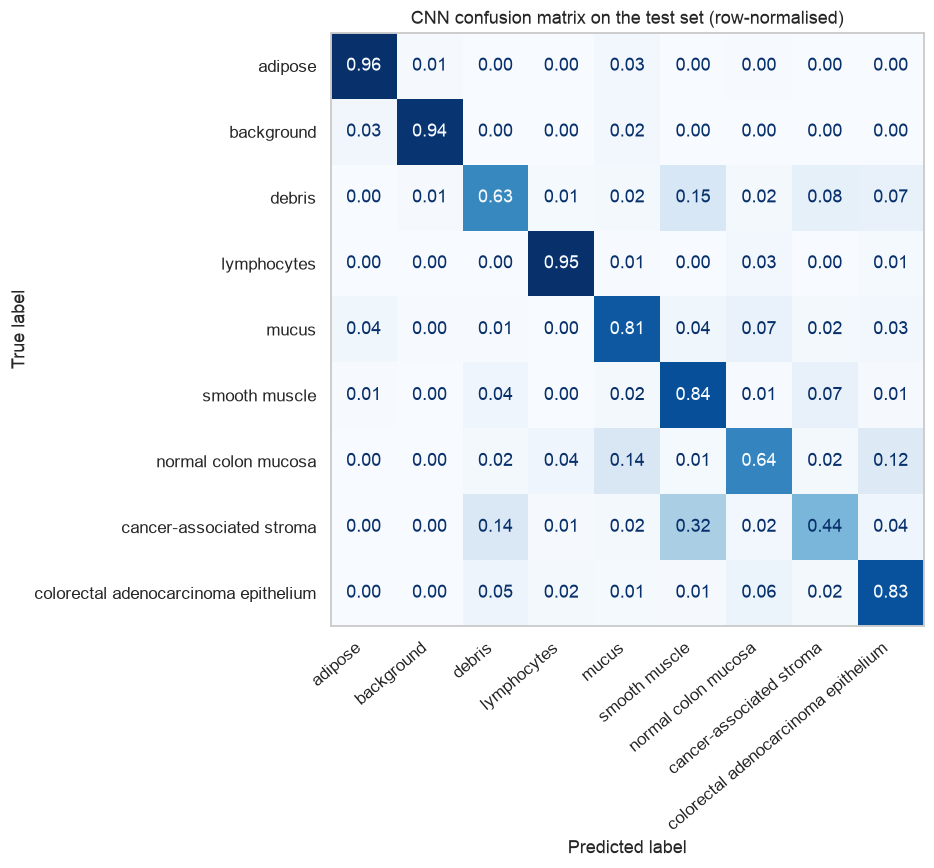

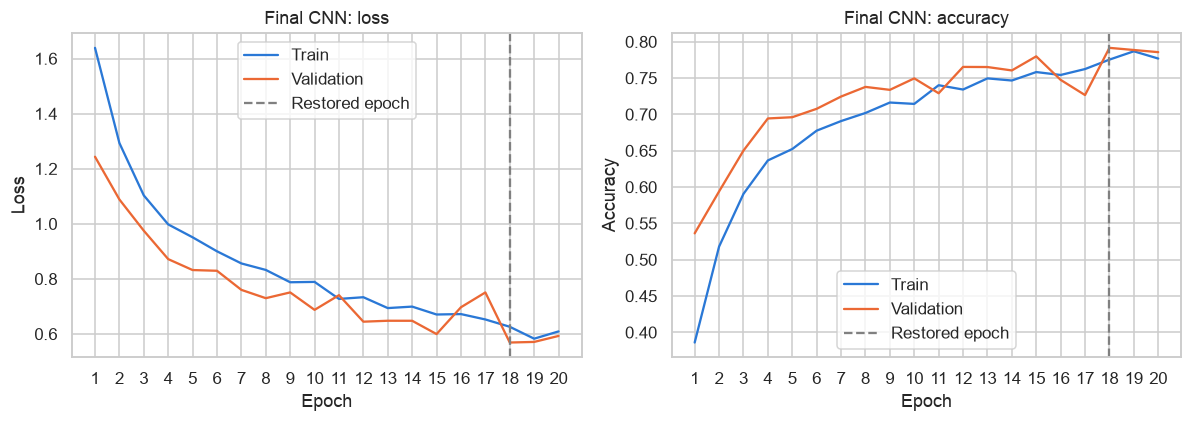

In [9]:
cnn_final_report = classification_report(
    y_te, cnn_test_pred, target_names=CLASS_NAMES, output_dict=True, zero_division=0,
)
cnn_final_class_table = pd.DataFrame({
    label: values for label, values in cnn_final_report.items() if isinstance(values, dict)
}).T
cnn_final_class_table["support"] = cnn_final_class_table["support"].astype(int)
cnn_final_class_table.to_csv(RESULTS_DIR / "cnn_classification_report.csv", index_label="class")
print(classification_report(y_te, cnn_test_pred, target_names=CLASS_NAMES, digits=3, zero_division=0))
plot_confusion(
    y_te, cnn_test_pred, "CNN confusion matrix on the test set (row-normalised)", "cnn_confusion_matrix",
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(axes, ["loss", "accuracy"], ["Loss", "Accuracy"]):
    ax.plot(cnn_final_history_table["epoch"], cnn_final_history_table[metric], label="Train", color=SERIES_BLUE)
    ax.plot(cnn_final_history_table["epoch"], cnn_final_history_table[f"val_{metric}"], label="Validation", color=SERIES_ORANGE)
    ax.axvline(cnn_final_best_epoch, color="grey", linestyle="--", label="Restored epoch")
    ax.set(xlabel="Epoch", ylabel=title, title=f"Final CNN: {title.lower()}")
    ax.set_xticks(cnn_final_history_table["epoch"])
    ax.legend()
fig.tight_layout()
save_fig(fig, "cnn_learning_curves")
plt.show()


## 5. AI Acknowledgement
Include acknowledgement of AI usage here. 
